# 4_phase-1

## 11.17.26 | ordination exploration

In [1]:
# Load packages
suppressPackageStartupMessages({
    library(vegan)
    library(phyloseq)
    library(tidyverse)
    library(data.table)
})
    
options(repr.plot.width=15, repr.plot.height=12)

In [2]:
# Read phyloseq object - bacteria ASVs as relative abundances
ps_bacteria <- readRDS("/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ps-objects/ps-dada2-rel-bacteria.rds")

In [3]:
# Subset phase 1 samples
ps <- subset_samples(ps_bacteria, Phase == 1 & Tissue != "filter")
ps <- prune_taxa(taxa_sums(ps) > 0, ps)
ps

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 10050 taxa and 48 samples ]
sample_data() Sample Data:       [ 48 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 10050 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 10050 reference sequences ]

Using bray-curtis distance matrix to ordinate data via PCoA and nMDS. Looking for clusters based on tissue type as well as beta-diversity patterns across Phase 1 based on treatment. 

### Include chloroplasts

In [3]:
# Compute bray-curtis distance matrix
dist_bray <- phyloseq::distance(ps, method = "bray")

# Ordinate using PCoA
pcoa_bray <- ordinate(ps, method = "PCoA", distance = dist_bray)
pcoa_bray$values$Relative_eig[1:5] %>% round(3)

# Ordinate using nMDS
nmds_bray <- ordinate(ps, method = "NMDS", distance = dist_bray)
nmds_bray$stress

[1] 0.208 0.081 0.078 0.072 0.056

Run 0 stress 0.1648777 
Run 1 stress 0.1840758 
Run 2 stress 0.1642882 
... New best solution
... Procrustes: rmse 0.04502203  max resid 0.2957815 
Run 3 stress 0.1714999 
Run 4 stress 0.1721393 
Run 5 stress 0.1711612 
Run 6 stress 0.1771886 
Run 7 stress 0.180873 
Run 8 stress 0.1806103 
Run 9 stress 0.1654761 
Run 10 stress 0.1632429 
... New best solution
... Procrustes: rmse 0.07293171  max resid 0.2470085 
Run 11 stress 0.1822444 
Run 12 stress 0.1829686 
Run 13 stress 0.1736903 
Run 14 stress 0.1635714 
... Procrustes: rmse 0.04728422  max resid 0.265636 
Run 15 stress 0.1806761 
Run 16 stress 0.1686728 
Run 17 stress 0.1613758 
... New best solution
... Procrustes: rmse 0.04456662  max resid 0.2647897 
Run 18 stress 0.1787372 
Run 19 stress 0.1664787 
Run 20 stress 0.1804101 
*** Best solution was not repeated -- monoMDS stopping criteria:
     1: no. of iterations >= maxit
    19: stress ratio > sratmax


[1] 0.1613758

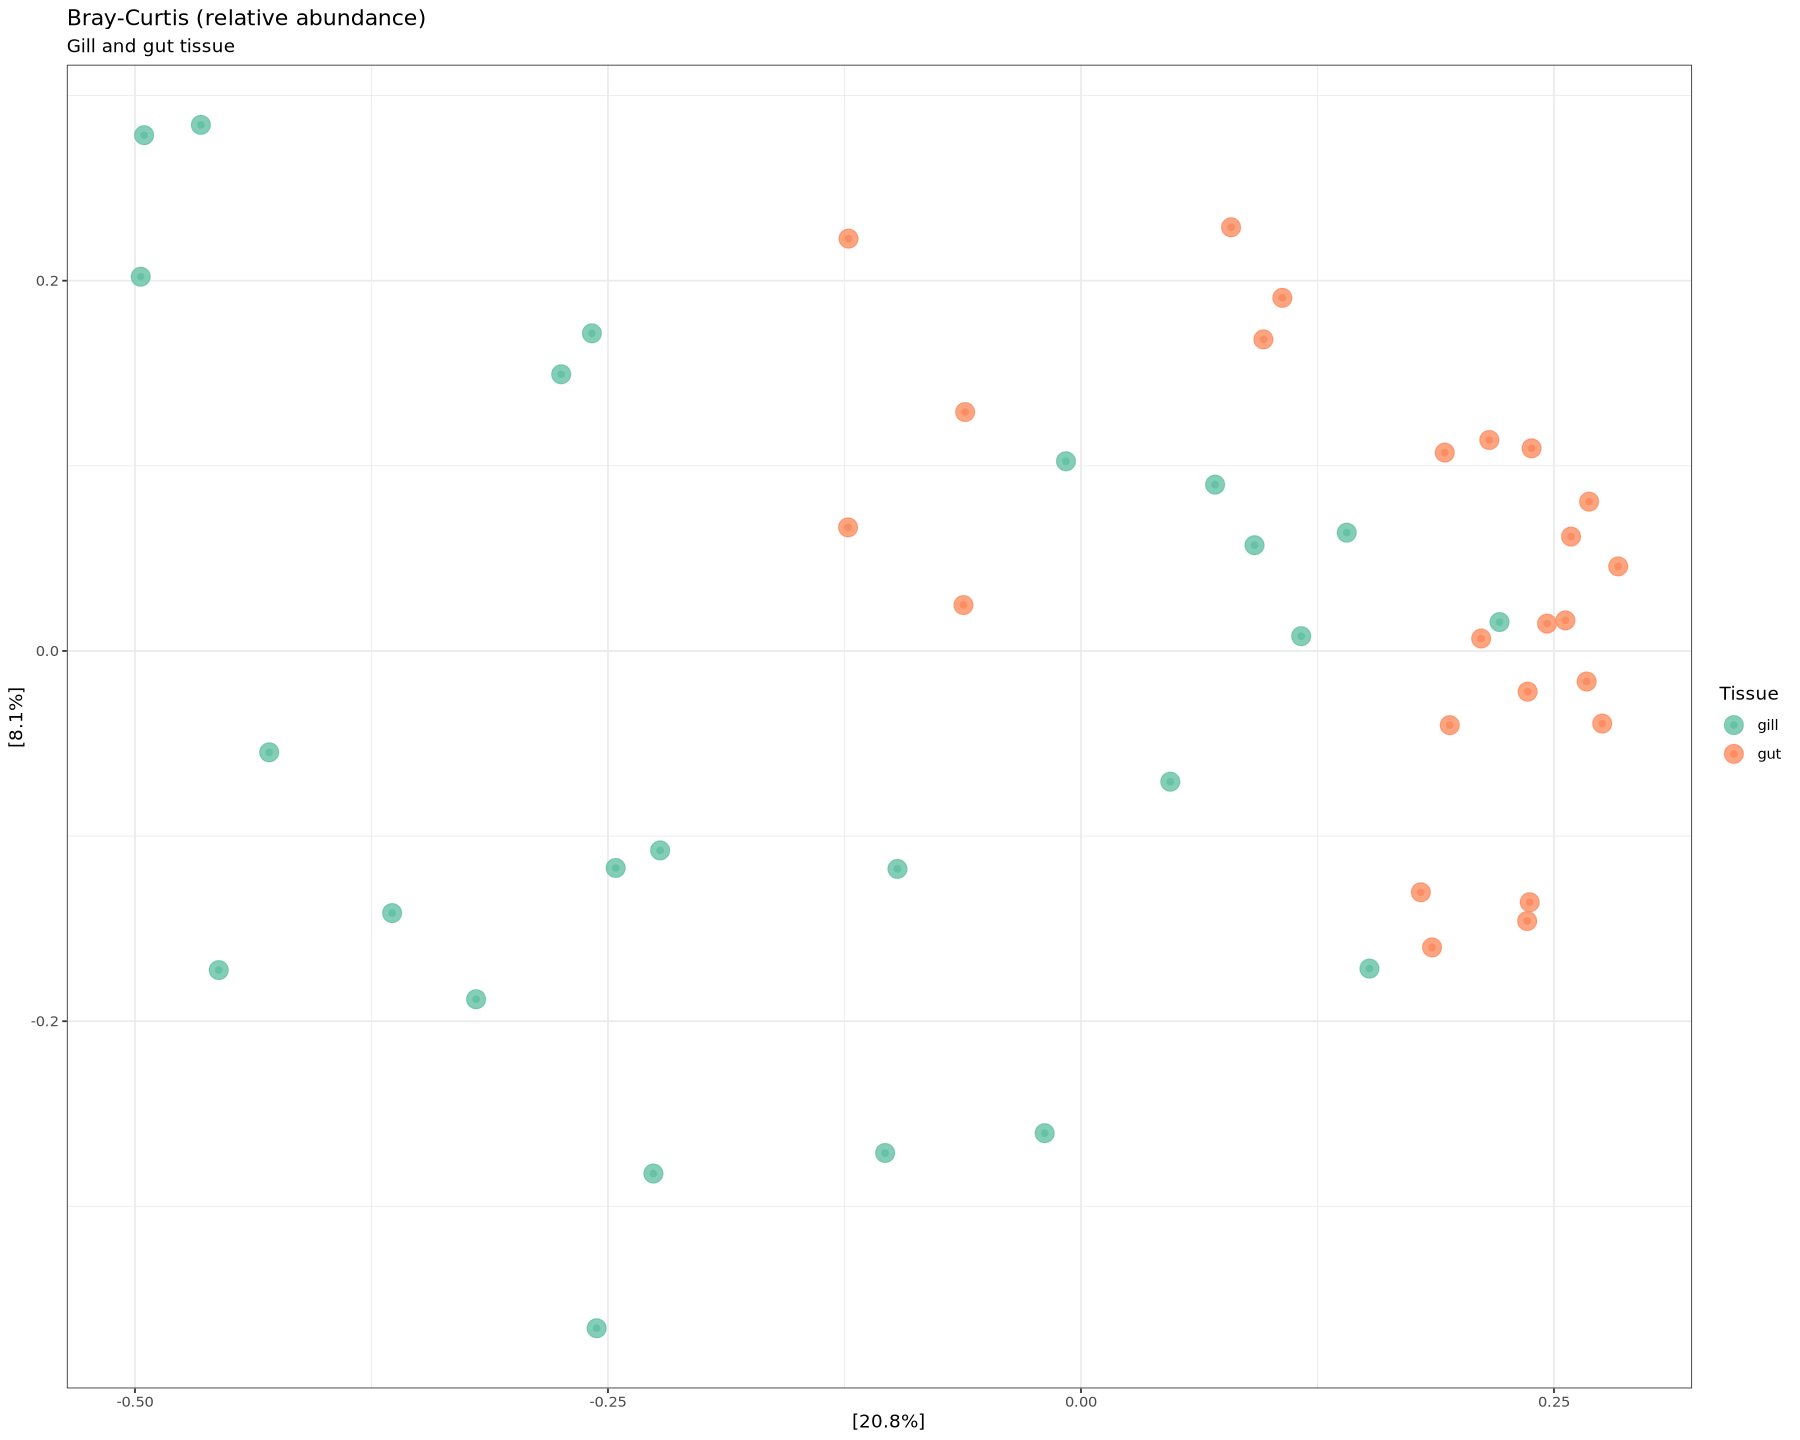

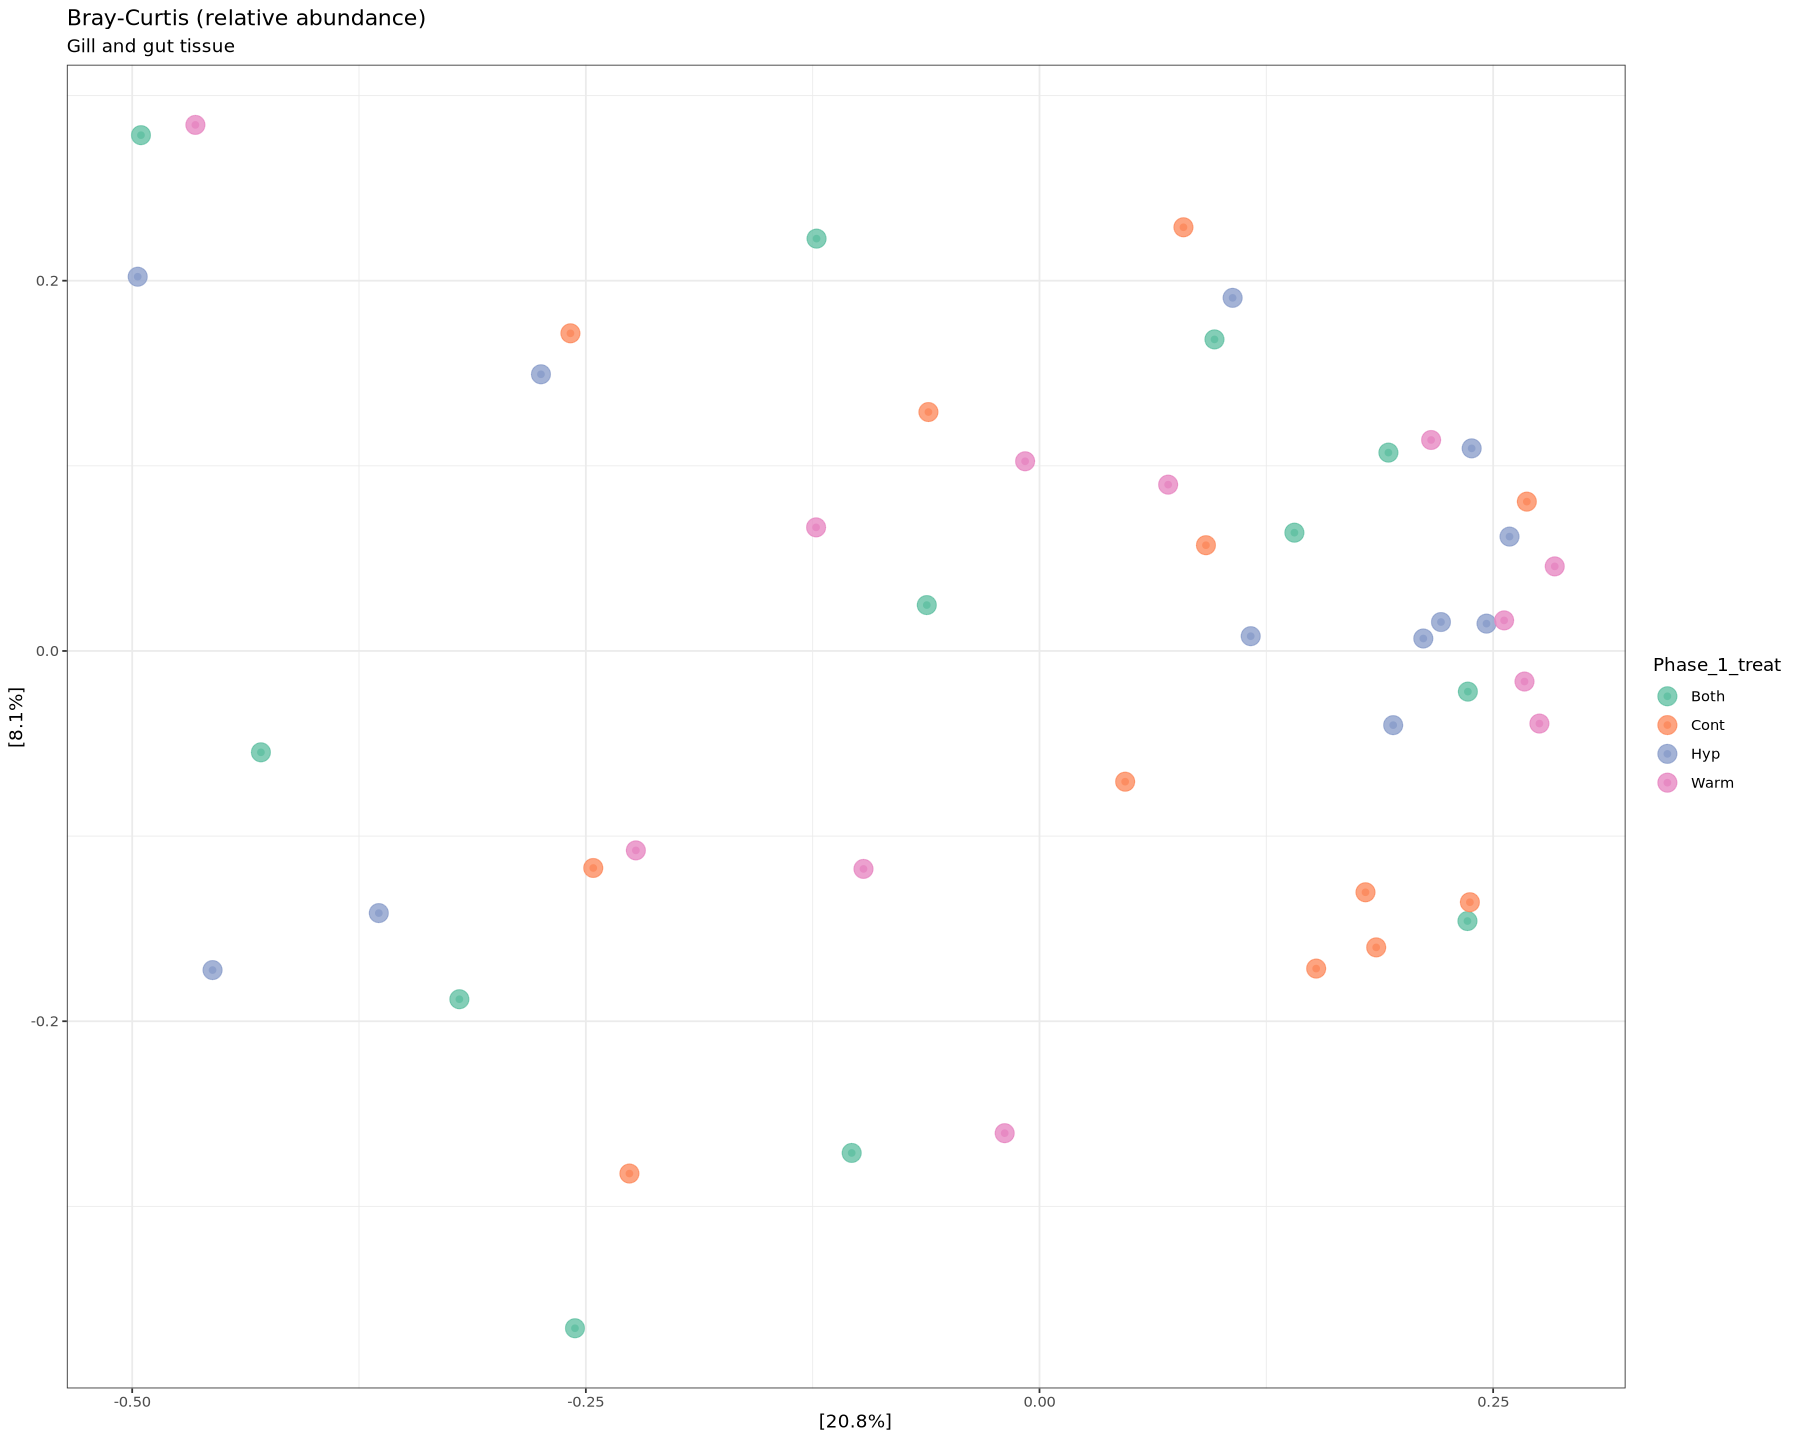

In [151]:
# Visualize PCoA
plot_ordination(ps, pcoa_bray, color = "Tissue") +
    geom_point(size = 5, alpha = 0.8) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "Bray-Curtis (relative abundance)", subtitle = "Gill and gut tissue") +
    theme_bw()

plot_ordination(ps, pcoa_bray, color = "Phase_1_treat") +
    geom_point(size = 5, alpha = 0.8) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "Bray-Curtis (relative abundance)", subtitle = "Gill and gut tissue") +
    theme_bw()

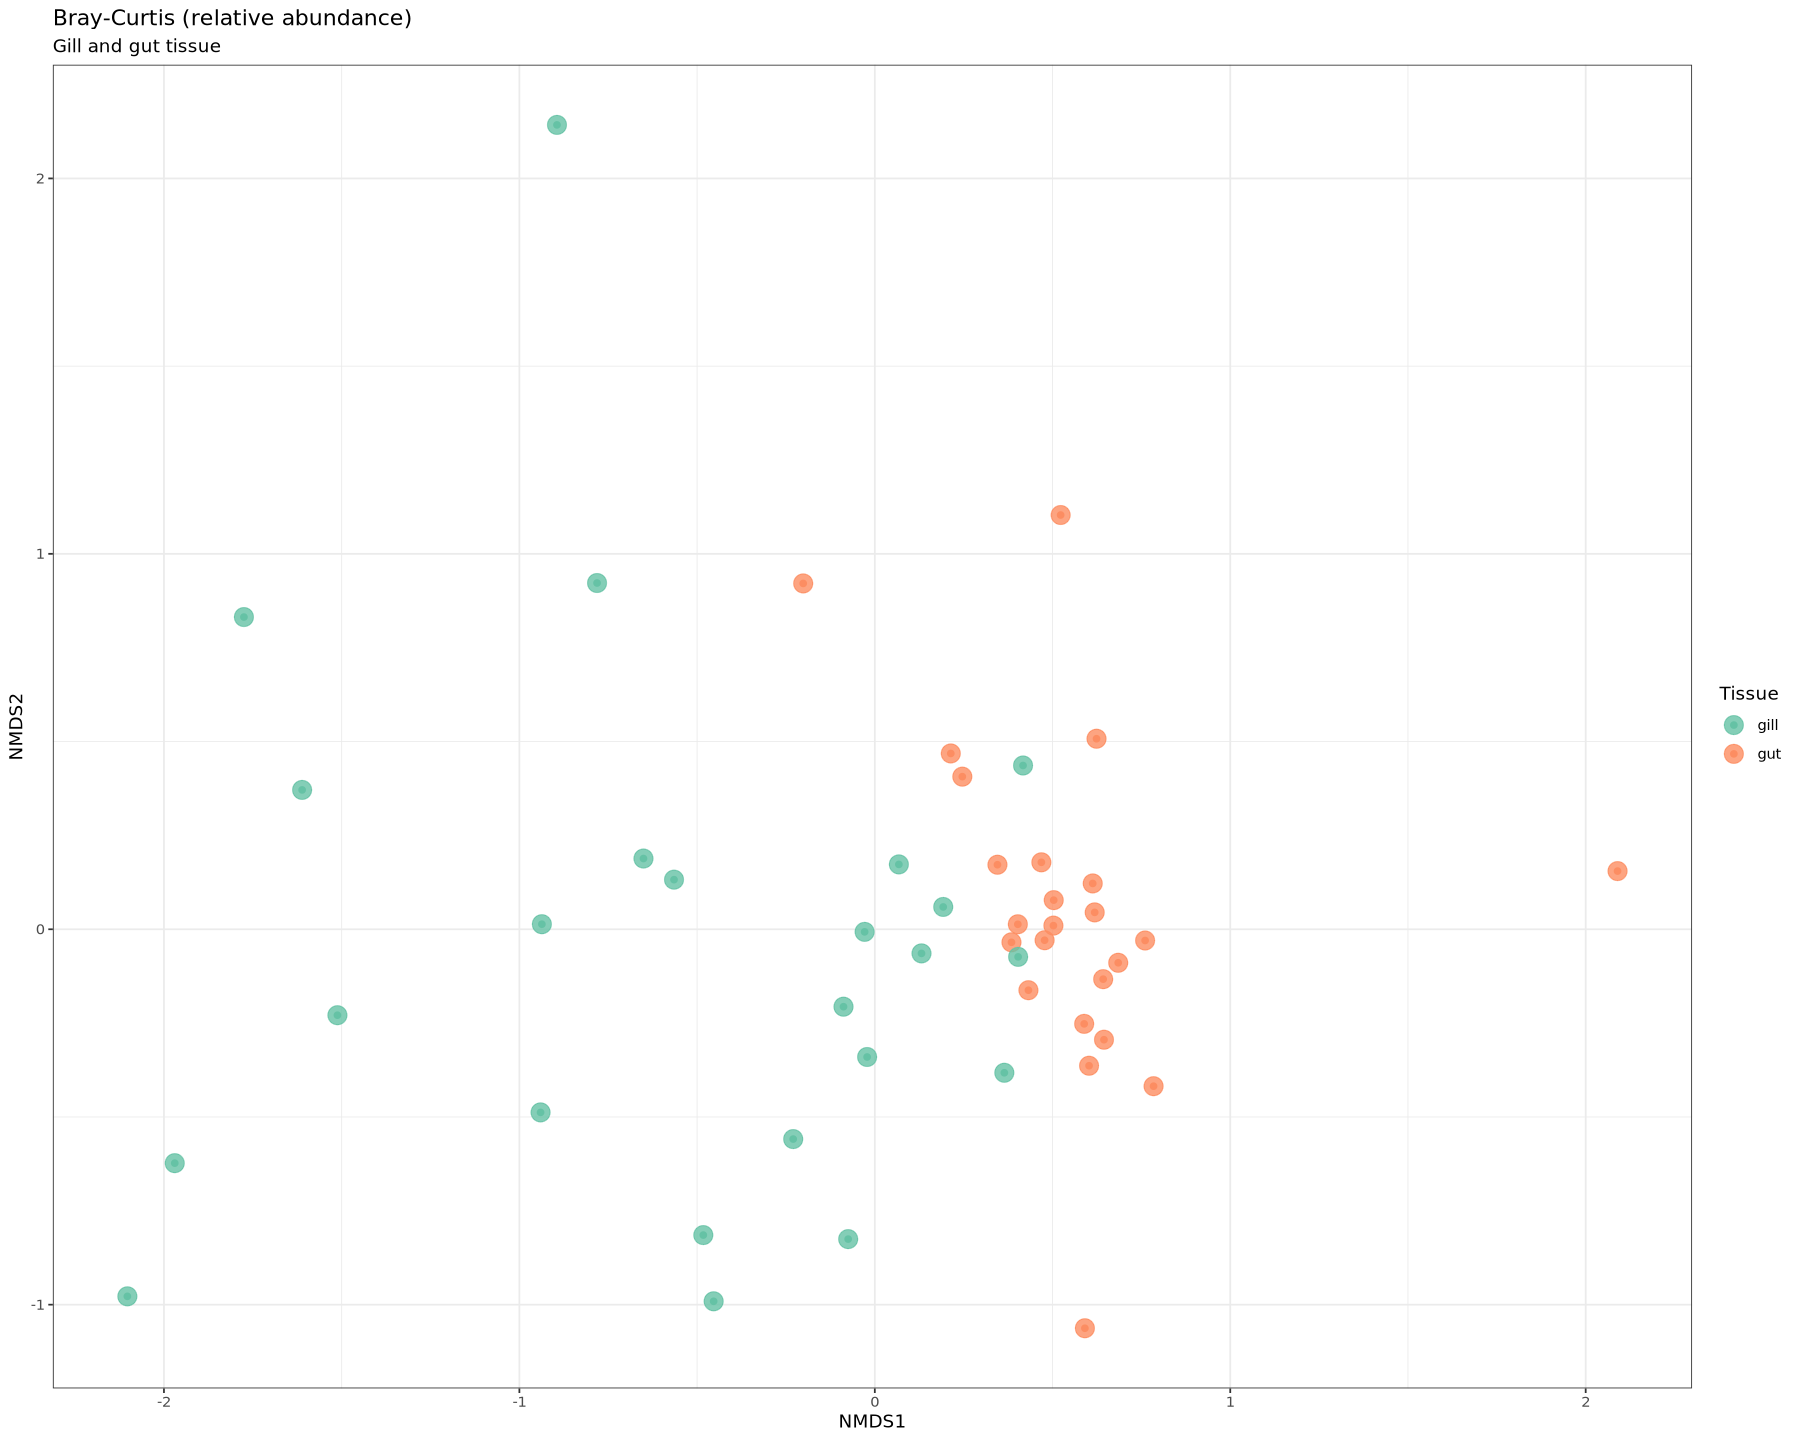

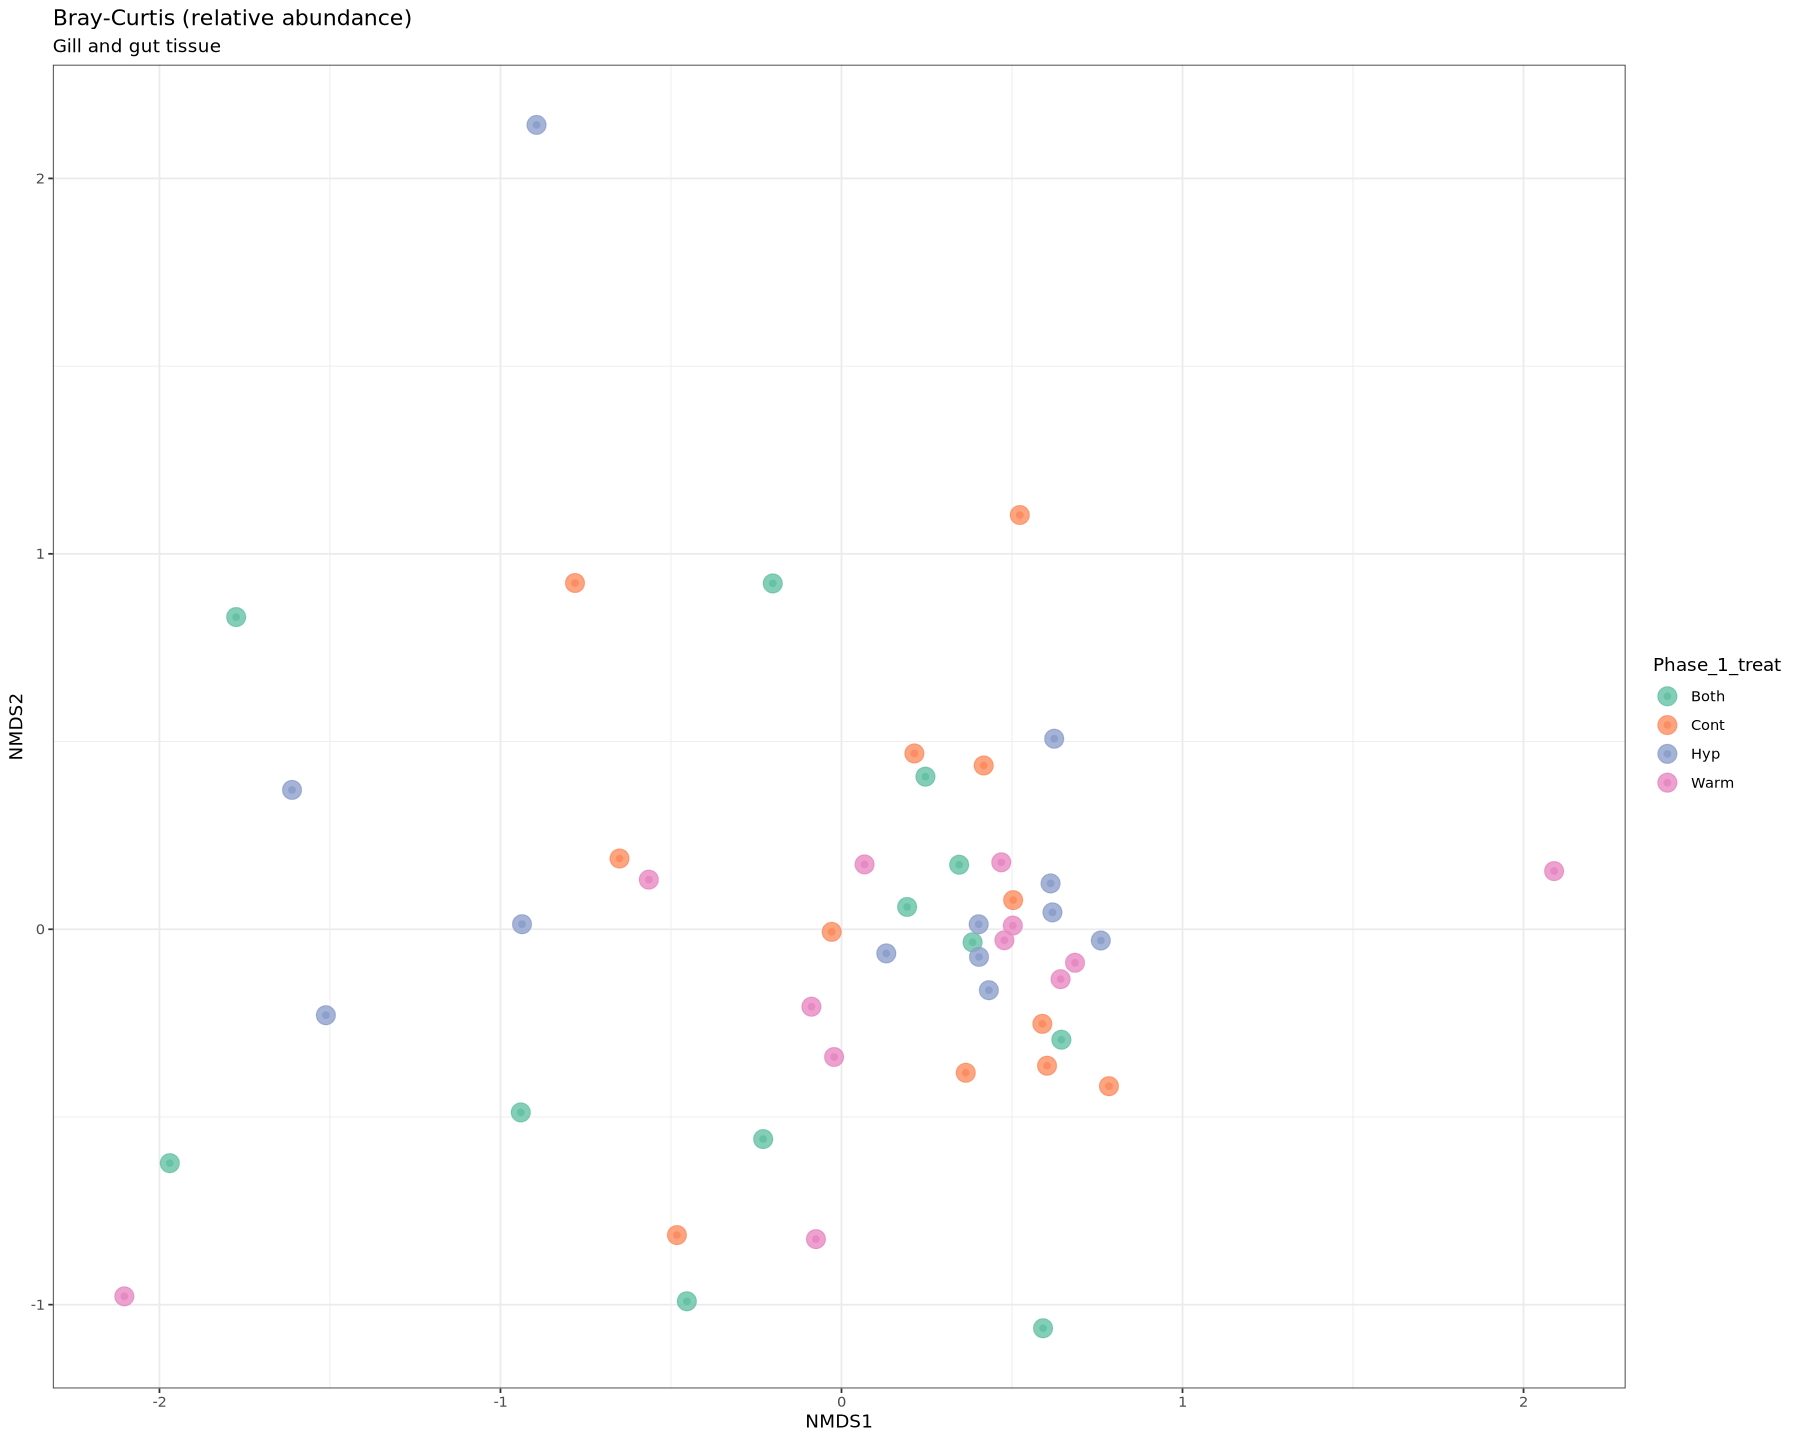

In [152]:
# Visualize nMDS
plot_ordination(ps, nmds_bray, type = "samples", color = "Tissue") +
    geom_point(size = 5, alpha = 0.8) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "Bray-Curtis (relative abundance)", subtitle = "Gill and gut tissue") +
    theme_bw() 

plot_ordination(ps, nmds_bray, type = "samples", color = "Phase_1_treat") +
    geom_point(size = 5, alpha = 0.8) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "Bray-Curtis (relative abundance)", subtitle = "Gill and gut tissue") +
    theme_bw() 

nMDS shows more distinct clustering based on tissue type than PCoA - likely because gut appears to be more tightly clustered than gill. No broad patterns in beta-diversity according to Phase 1 treatment. 

In [11]:
saveRDS(ps, "/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ps-objects/ps-dada2-p1.rds")

### Remove chloroplasts

In [4]:
# Remove chloroplasts
ps_nc <- subset_taxa(ps, Order != "Chloroplast")
ps_nc <- prune_taxa(taxa_sums(ps_nc) > 0, ps_nc)
ps_nc

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 8705 taxa and 48 samples ]
sample_data() Sample Data:       [ 48 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 8705 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 8705 reference sequences ]

In [5]:
# Compute bray-curtis distance matrix
dist_bray_nc <- phyloseq::distance(ps_nc, method = "bray")

# Ordinate using PCoA
pcoa_bray_nc <- ordinate(ps_nc, method = "PCoA", distance = dist_bray_nc)
pcoa_bray_nc$values$Relative_eig[1:5] %>% round(3)

# Ordinate using nMDS
nmds_bray_nc <- ordinate(ps_nc, method = "NMDS", distance = dist_bray_nc)
nmds_bray_nc$stress

[1] 0.213 0.082 0.080 0.070 0.057

Run 0 stress 0.1799811 
Run 1 stress 0.1728098 
... New best solution
... Procrustes: rmse 0.1051982  max resid 0.3115416 
Run 2 stress 0.1755148 
Run 3 stress 0.170566 
... New best solution
... Procrustes: rmse 0.08531872  max resid 0.4475466 
Run 4 stress 0.1787139 
Run 5 stress 0.1826989 
Run 6 stress 0.182288 
Run 7 stress 0.1823204 
Run 8 stress 0.1766955 
Run 9 stress 0.1795116 
Run 10 stress 0.1727849 
Run 11 stress 0.1668981 
... New best solution
... Procrustes: rmse 0.08055636  max resid 0.2949925 
Run 12 stress 0.1715543 
Run 13 stress 0.1746095 
Run 14 stress 0.1707021 
Run 15 stress 0.1859554 
Run 16 stress 0.185277 
Run 17 stress 0.1734468 
Run 18 stress 0.1658861 
... New best solution
... Procrustes: rmse 0.06807818  max resid 0.2375669 
Run 19 stress 0.175868 
Run 20 stress 0.1788854 
*** Best solution was not repeated -- monoMDS stopping criteria:
    20: stress ratio > sratmax


[1] 0.1658861

Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the phyloseq package.
  Please report the issue at <https://github.com/joey711/phyloseq/issues>.”


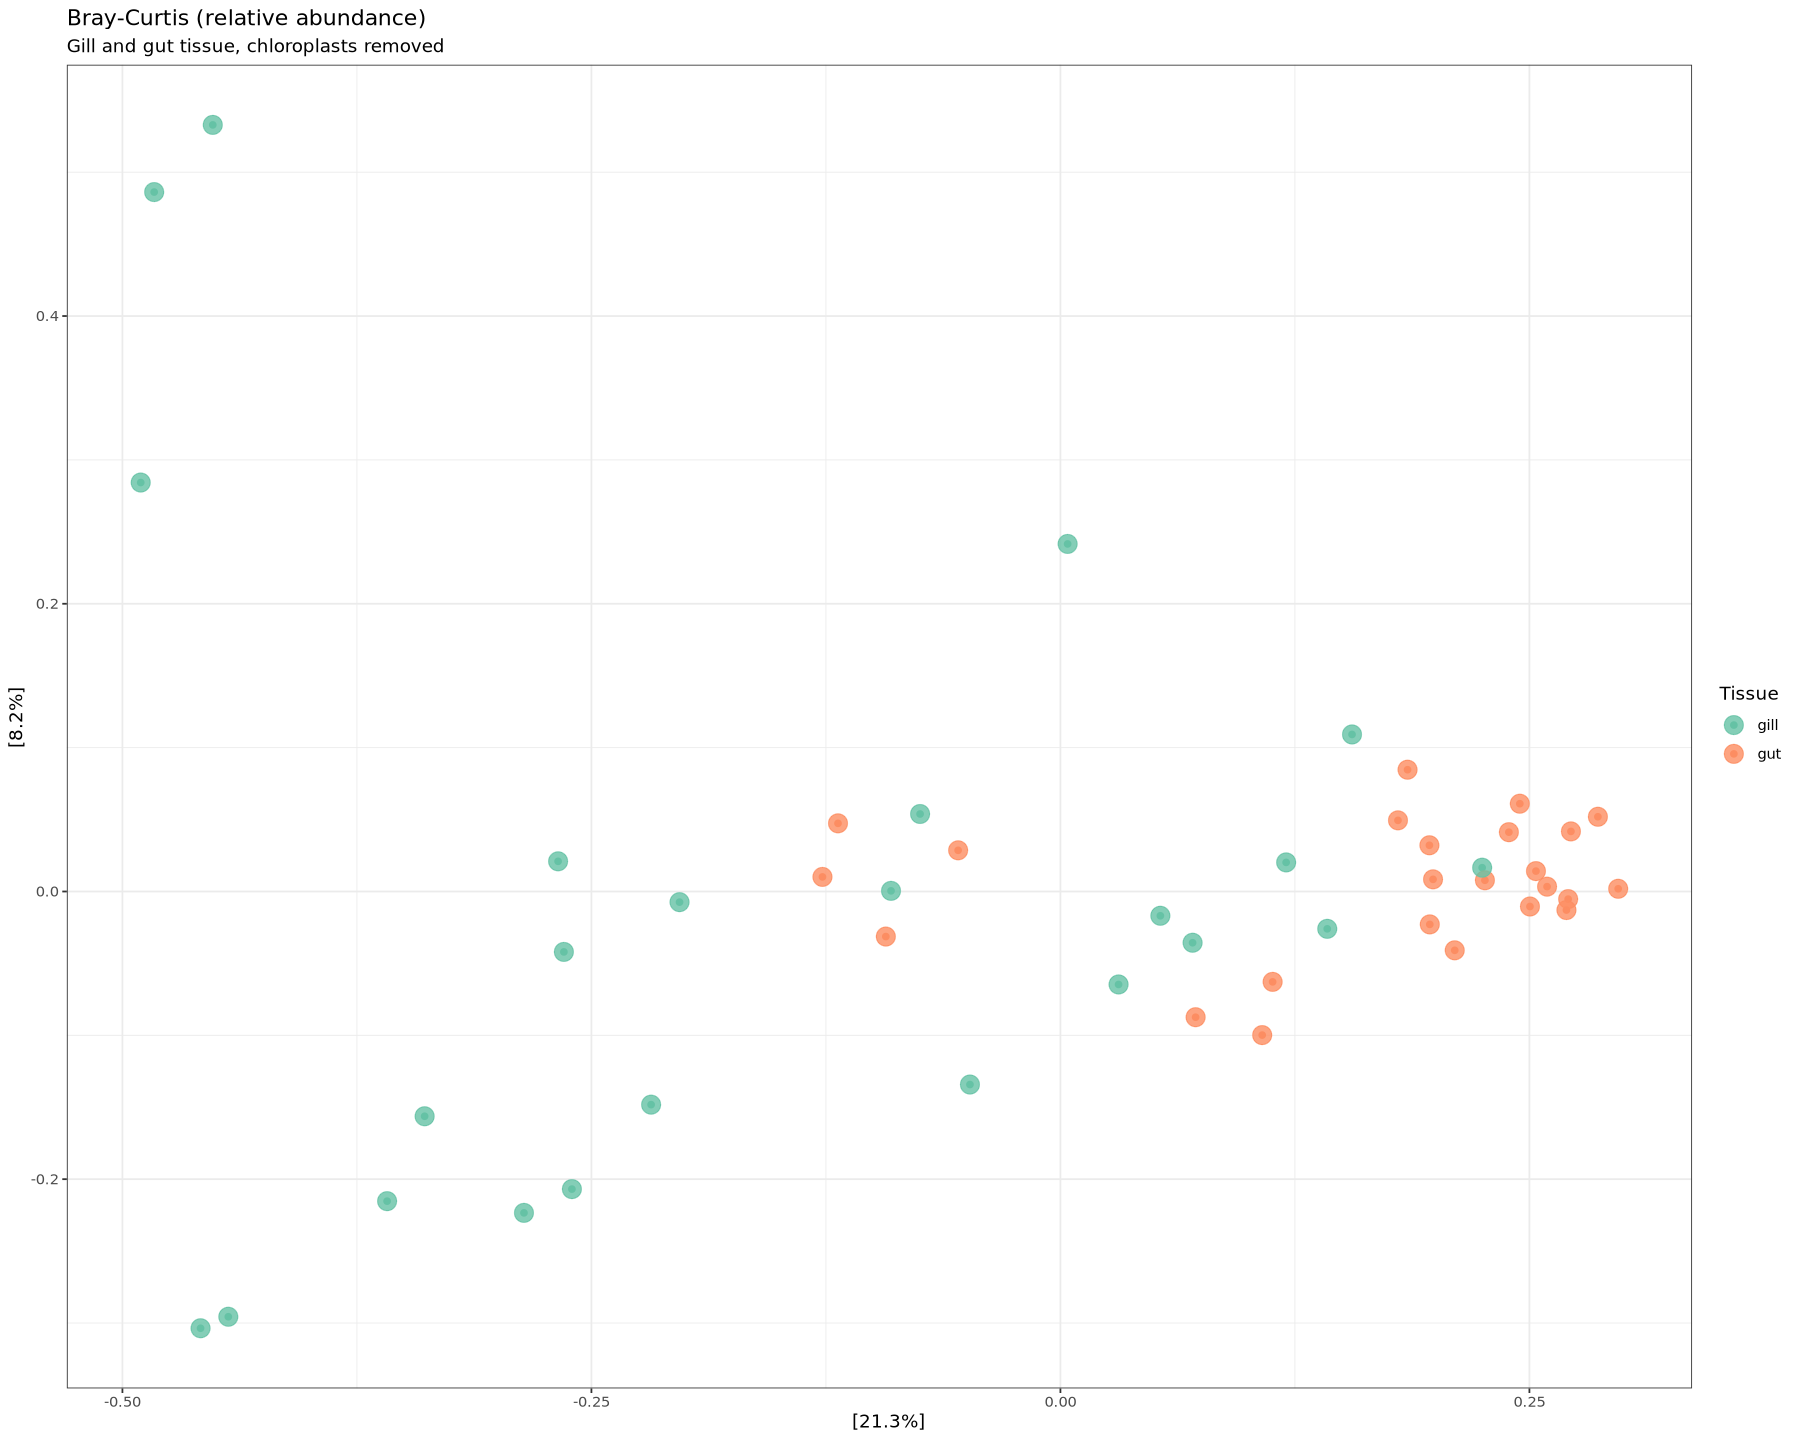

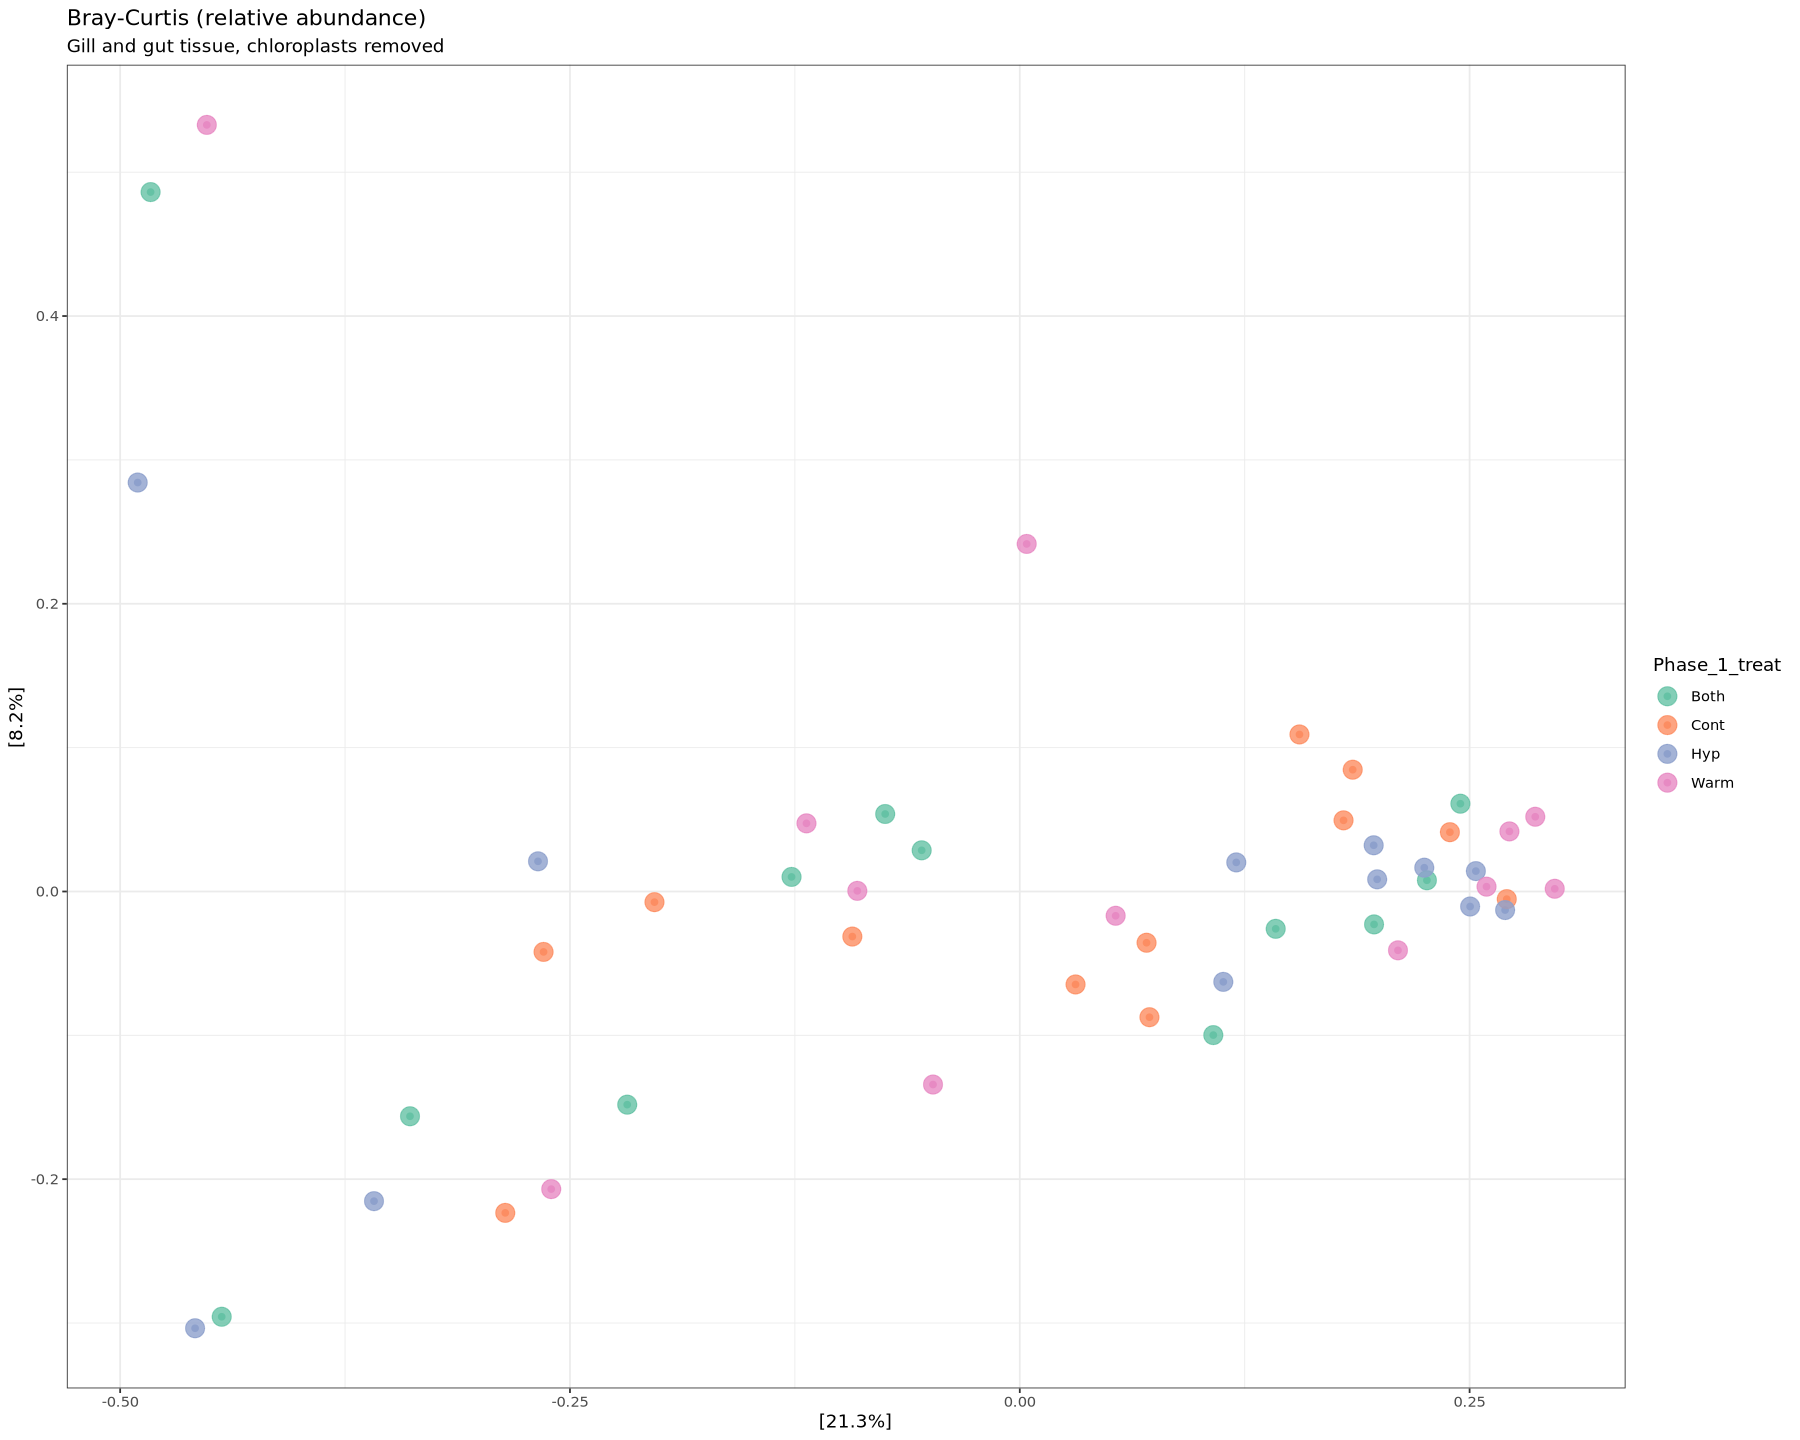

In [9]:
# Visualize PCoA
plot_ordination(ps_nc, pcoa_bray_nc, color = "Tissue") +
    geom_point(size = 5, alpha = 0.8) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "Bray-Curtis (relative abundance)", subtitle = "Gill and gut tissue, chloroplasts removed") +
    theme_bw()

plot_ordination(ps_nc, pcoa_bray_nc, color = "Phase_1_treat") +
    geom_point(size = 5, alpha = 0.8) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "Bray-Curtis (relative abundance)", subtitle = "Gill and gut tissue, chloroplasts removed") +
    theme_bw()

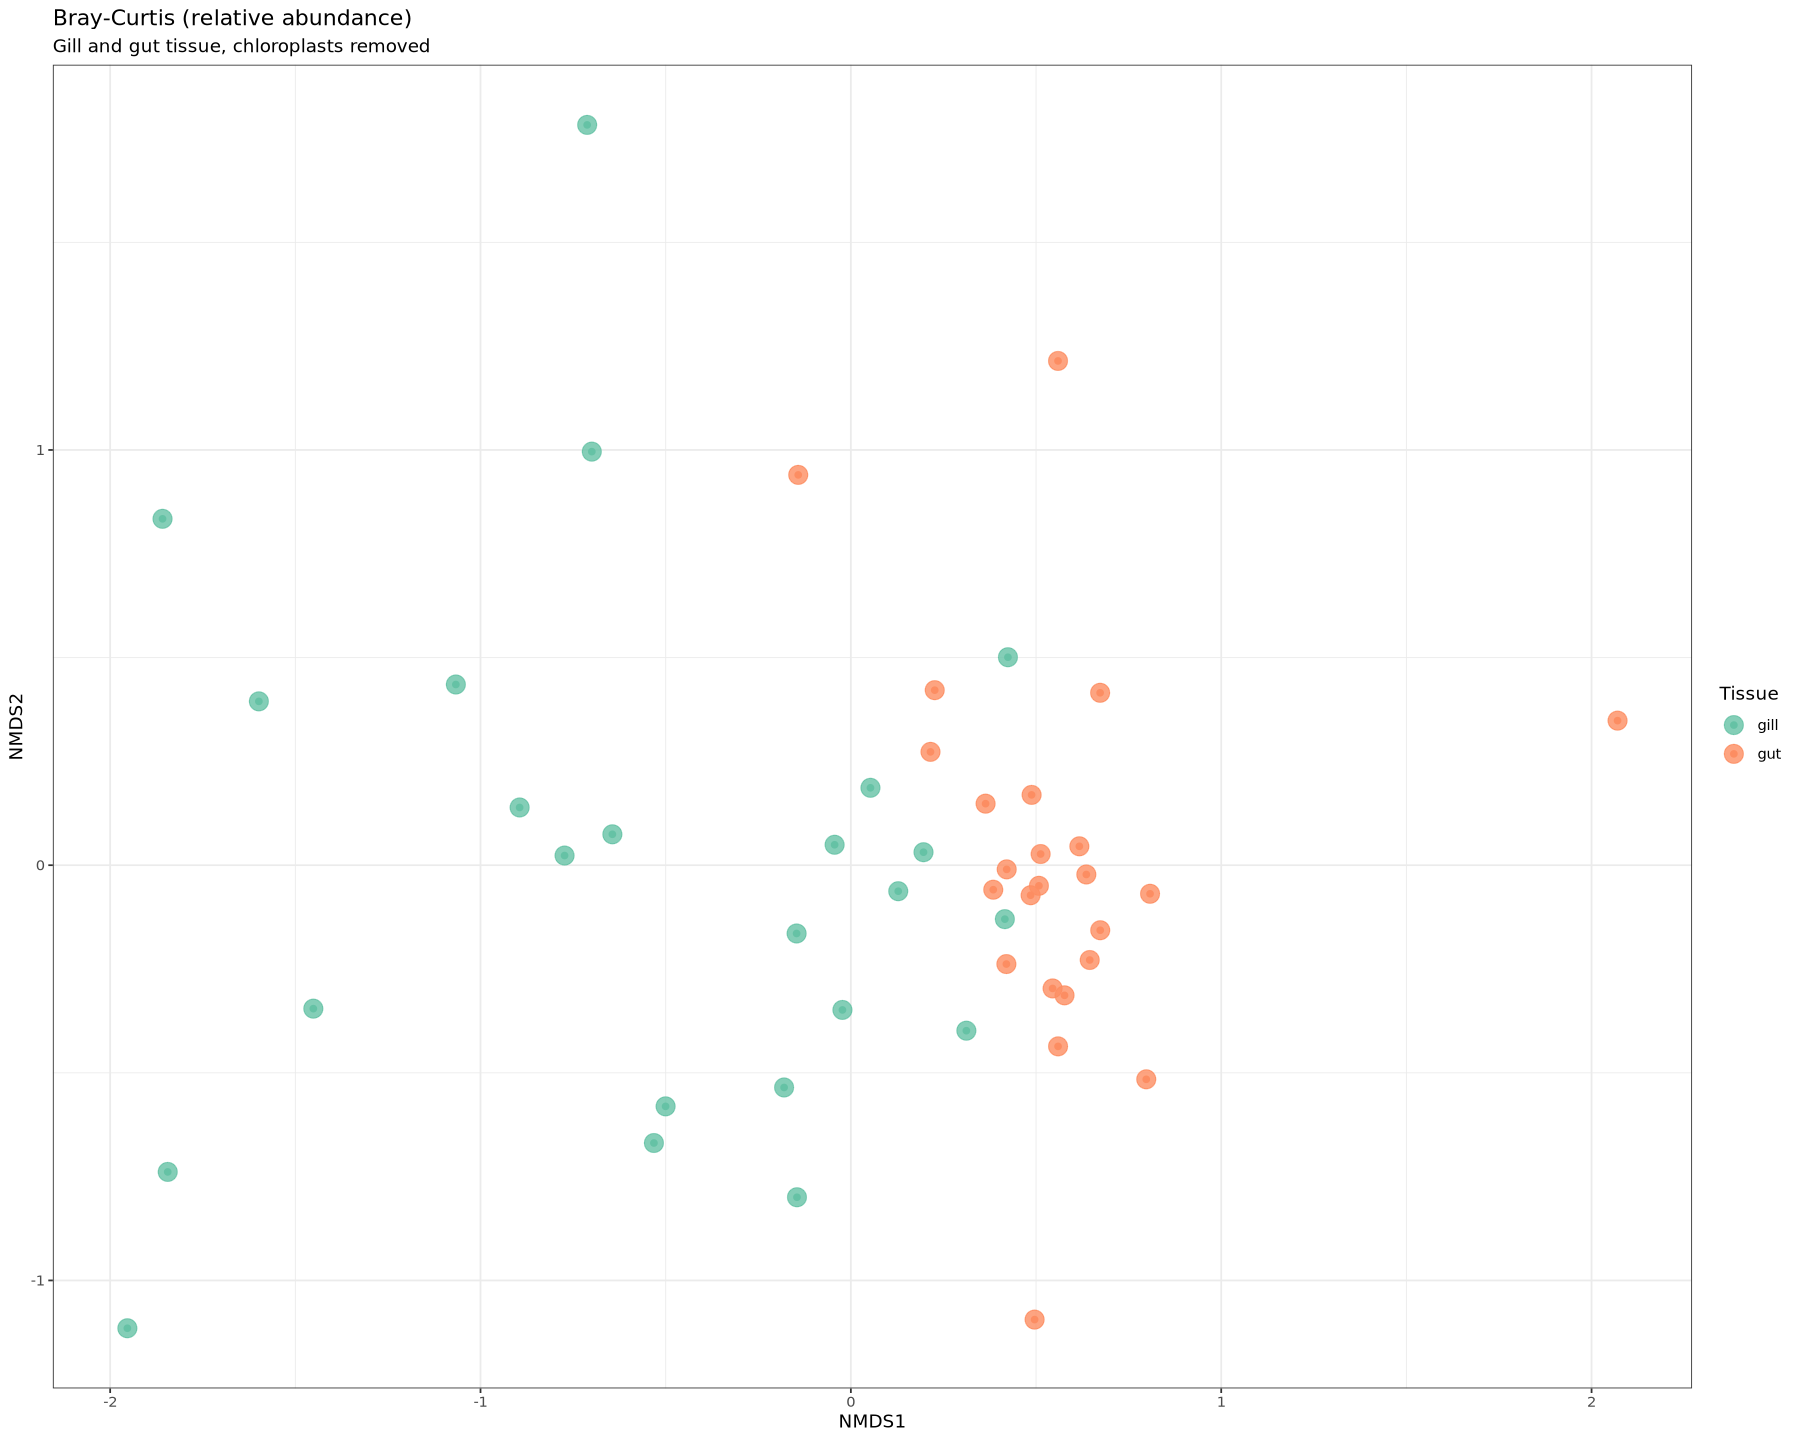

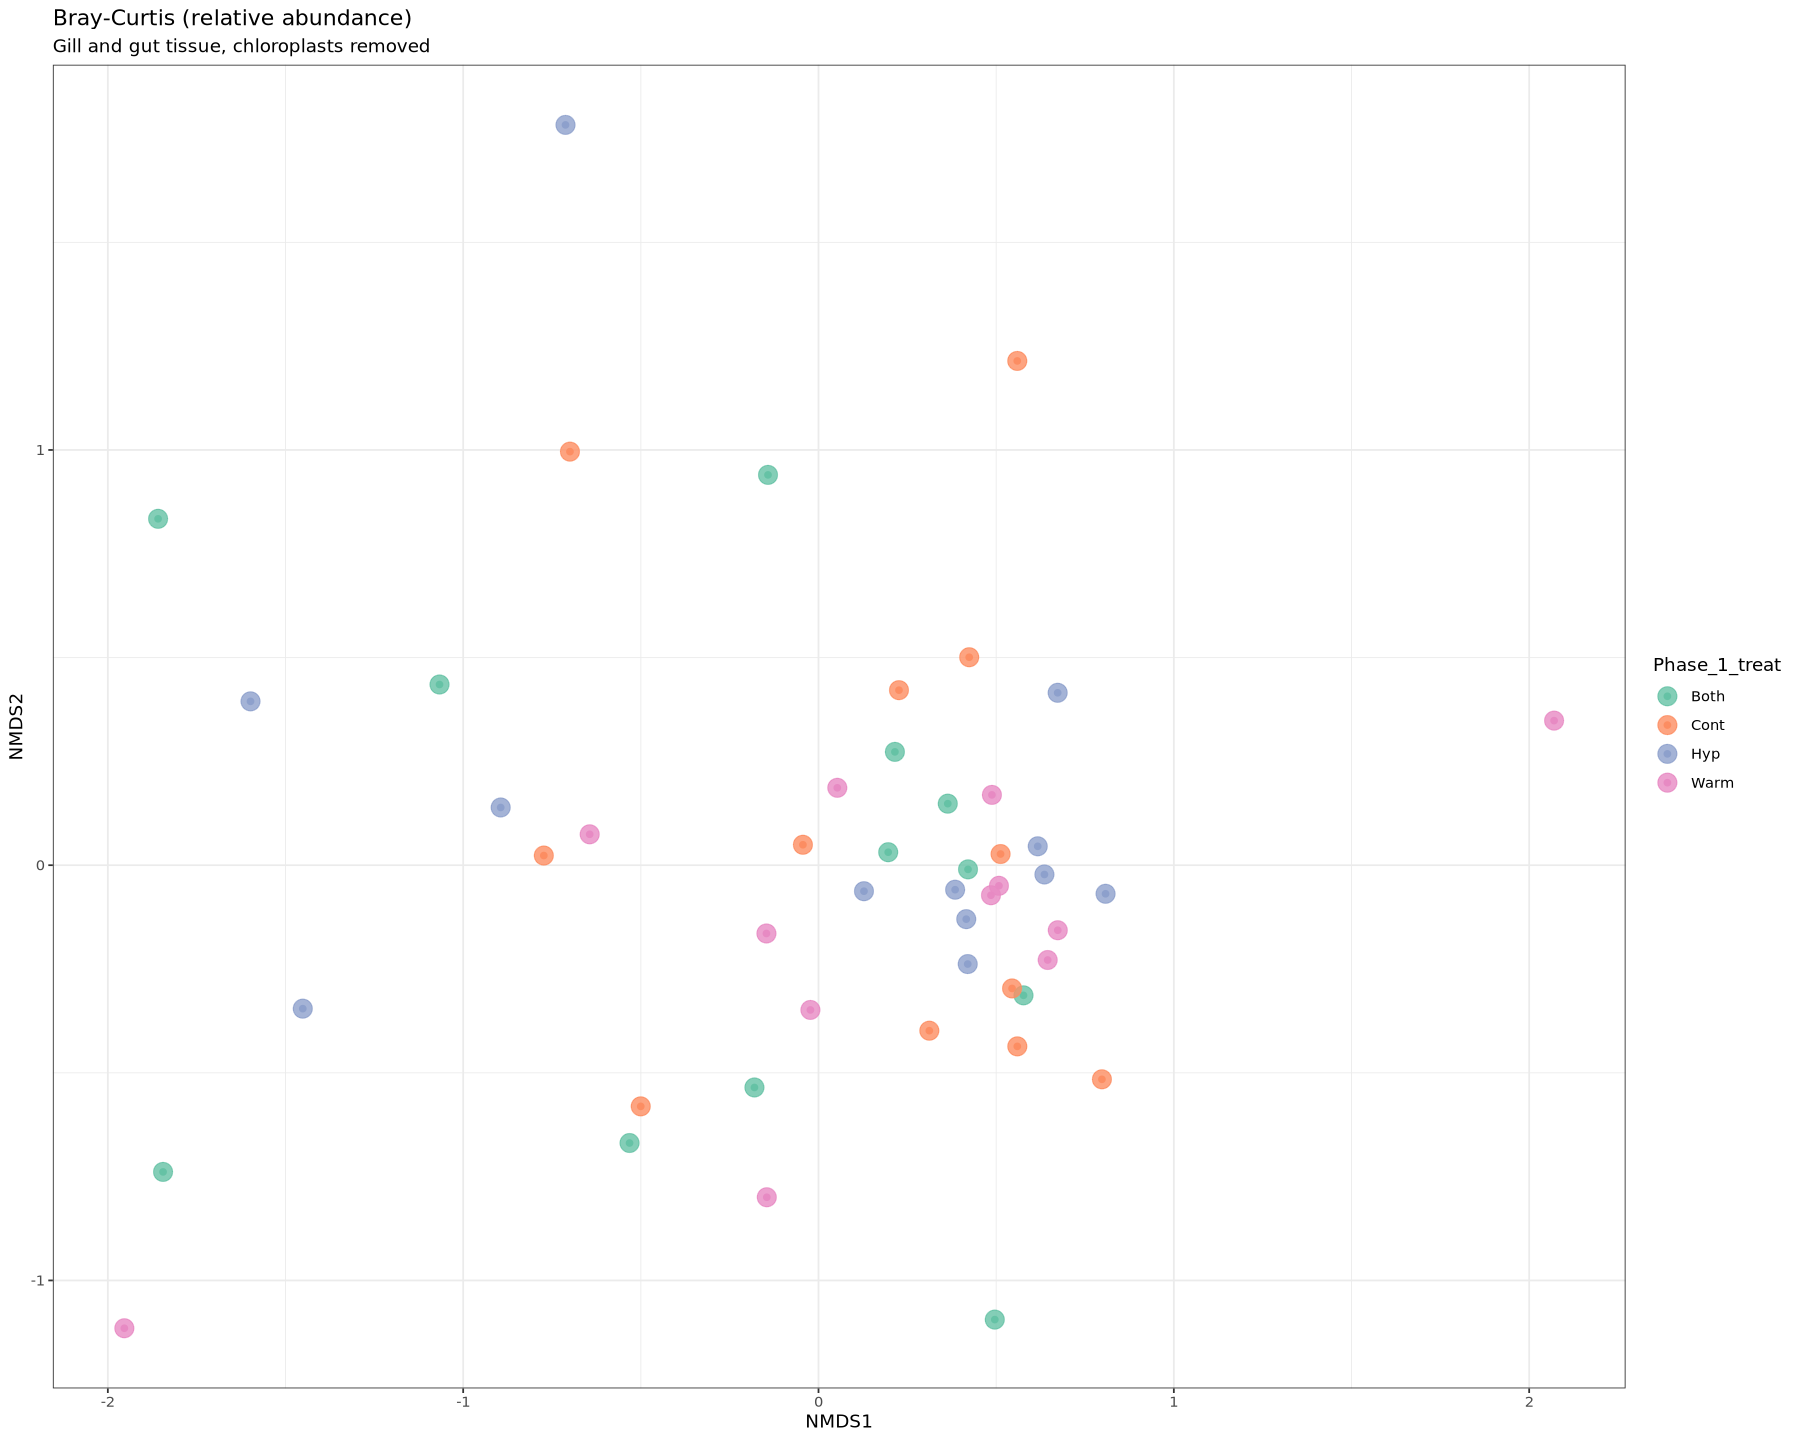

In [10]:
# Visualize nMDS
plot_ordination(ps_nc, nmds_bray_nc, type = "samples", color = "Tissue") +
    geom_point(size = 5, alpha = 0.8) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "Bray-Curtis (relative abundance)", subtitle = "Gill and gut tissue, chloroplasts removed") +
    theme_bw() 

plot_ordination(ps_nc, nmds_bray_nc, type = "samples", color = "Phase_1_treat") +
    geom_point(size = 5, alpha = 0.8) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "Bray-Curtis (relative abundance)", subtitle = "Gill and gut tissue, chloroplasts removed") +
    theme_bw() 

In [18]:
# Convert phyloseq object sample data into metadata df
metadata <- data.frame(sample_data(ps_nc))

# Align metadata with distance matrix
metadata <- metadata[labels(dist_bray_nc), , drop = FALSE]

In [32]:
# PERMANOVA - tissue differences
permanova_tissue <- adonis2(dist_bray_nc ~ Tissue, data = metadata, permutations = 999, strata = metadata$Tag)
permanova_tissue

,Df,SumOfSqs,R2,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Model,1,1.526074,0.1123764,5.823767,0.001
Residual,46,12.053949,0.8876236,NA,NA
Total,47,13.580022,1.0000000,NA,NA


Tissue explains 11% of the variation in microbiome composition and is a signficant effect (P = 0.001) while accounting for the fact that different tissues were sampled from the same animal. 

In [41]:
# Check beta dispersion (variability within each treatment group)
disp_tissue <- betadisper(dist_bray_nc, metadata$Tissue)
permutest(disp_tissue, permutations = 999)


Permutation test for homogeneity of multivariate dispersions
Permutation: free
Number of permutations: 999

Response: Distances
          Df  Sum Sq  Mean Sq      F N.Perm Pr(>F)   
Groups     1 0.13383 0.133829 10.152    999  0.004 **
Residuals 46 0.60637 0.013182                        
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

The two tissue types vary significantly in the amount of microbiome composition dispersion/variation. Looking at the PCoA and nMDS, it's likely that gut has more dispersion which may be influencing the significant difference between tissue types we found using PERMANOVA. 

In [39]:
# PERMANOVA - model both variables
permanova <- adonis2(dist_bray_nc ~ Tissue * Phase_1_treat, data = metadata, by = "margin", permutations = 999)
permanova

,Df,SumOfSqs,R2,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Tissue:Phase_1_treat,3,0.5720339,0.04212319,0.7137804,0.961
Residual,40,10.6855253,0.78685624,NA,NA
Total,47,13.5800223,1.00000000,NA,NA


Need to interpret the interaction effect, if this is even biologically relevant here - want to look at Phase 1 treatment per tissue independently (below)

### Gill only

Proceeding with chloroplasts removed, keeping with other published literature. 

In [6]:
# Keep only gill
ps_gill <- subset_samples(ps_nc, Tissue == "gill")
ps_gill <- prune_taxa(taxa_sums(ps_gill) > 0, ps_gill)
ps_gill

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 4072 taxa and 24 samples ]
sample_data() Sample Data:       [ 24 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 4072 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 4072 reference sequences ]

In [7]:
# Compute bray-curtis distance matrix
dist_bray_gill <- phyloseq::distance(ps_gill, method = "bray")

# Ordinate using PCoA
pcoa_bray_gill <- ordinate(ps_gill, method = "PCoA", distance = dist_bray_gill)
pcoa_bray_gill$values$Relative_eig[1:5] %>% round(3)

# Ordinate using nMDS
nmds_bray_gill <- ordinate(ps_gill, method = "NMDS", distance = dist_bray_gill)
nmds_bray_gill$stress

[1] 0.201 0.154 0.121 0.096 0.056

Run 0 stress 0.2092307 
Run 1 stress 0.2126318 
Run 2 stress 0.2079763 
... New best solution
... Procrustes: rmse 0.02896951  max resid 0.07155005 
Run 3 stress 0.2047262 
... New best solution
... Procrustes: rmse 0.1258104  max resid 0.5081357 
Run 4 stress 0.1945359 
... New best solution
... Procrustes: rmse 0.1701315  max resid 0.5928391 
Run 5 stress 0.194536 
... Procrustes: rmse 0.000167865  max resid 0.0006430256 
... Similar to previous best
Run 6 stress 0.2074771 
Run 7 stress 0.1884685 
... New best solution
... Procrustes: rmse 0.1764322  max resid 0.419307 
Run 8 stress 0.199185 
Run 9 stress 0.2127198 
Run 10 stress 0.2122941 
Run 11 stress 0.2281501 
Run 12 stress 0.2079382 
Run 13 stress 0.1936828 
Run 14 stress 0.2092959 
Run 15 stress 0.2079382 
Run 16 stress 0.1884689 
... Procrustes: rmse 0.0005315988  max resid 0.002056059 
... Similar to previous best
Run 17 stress 0.1884686 
... Procrustes: rmse 3.921715e-05  max resid 0.0001595241 
... Similar to previous best

[1] 0.1884685

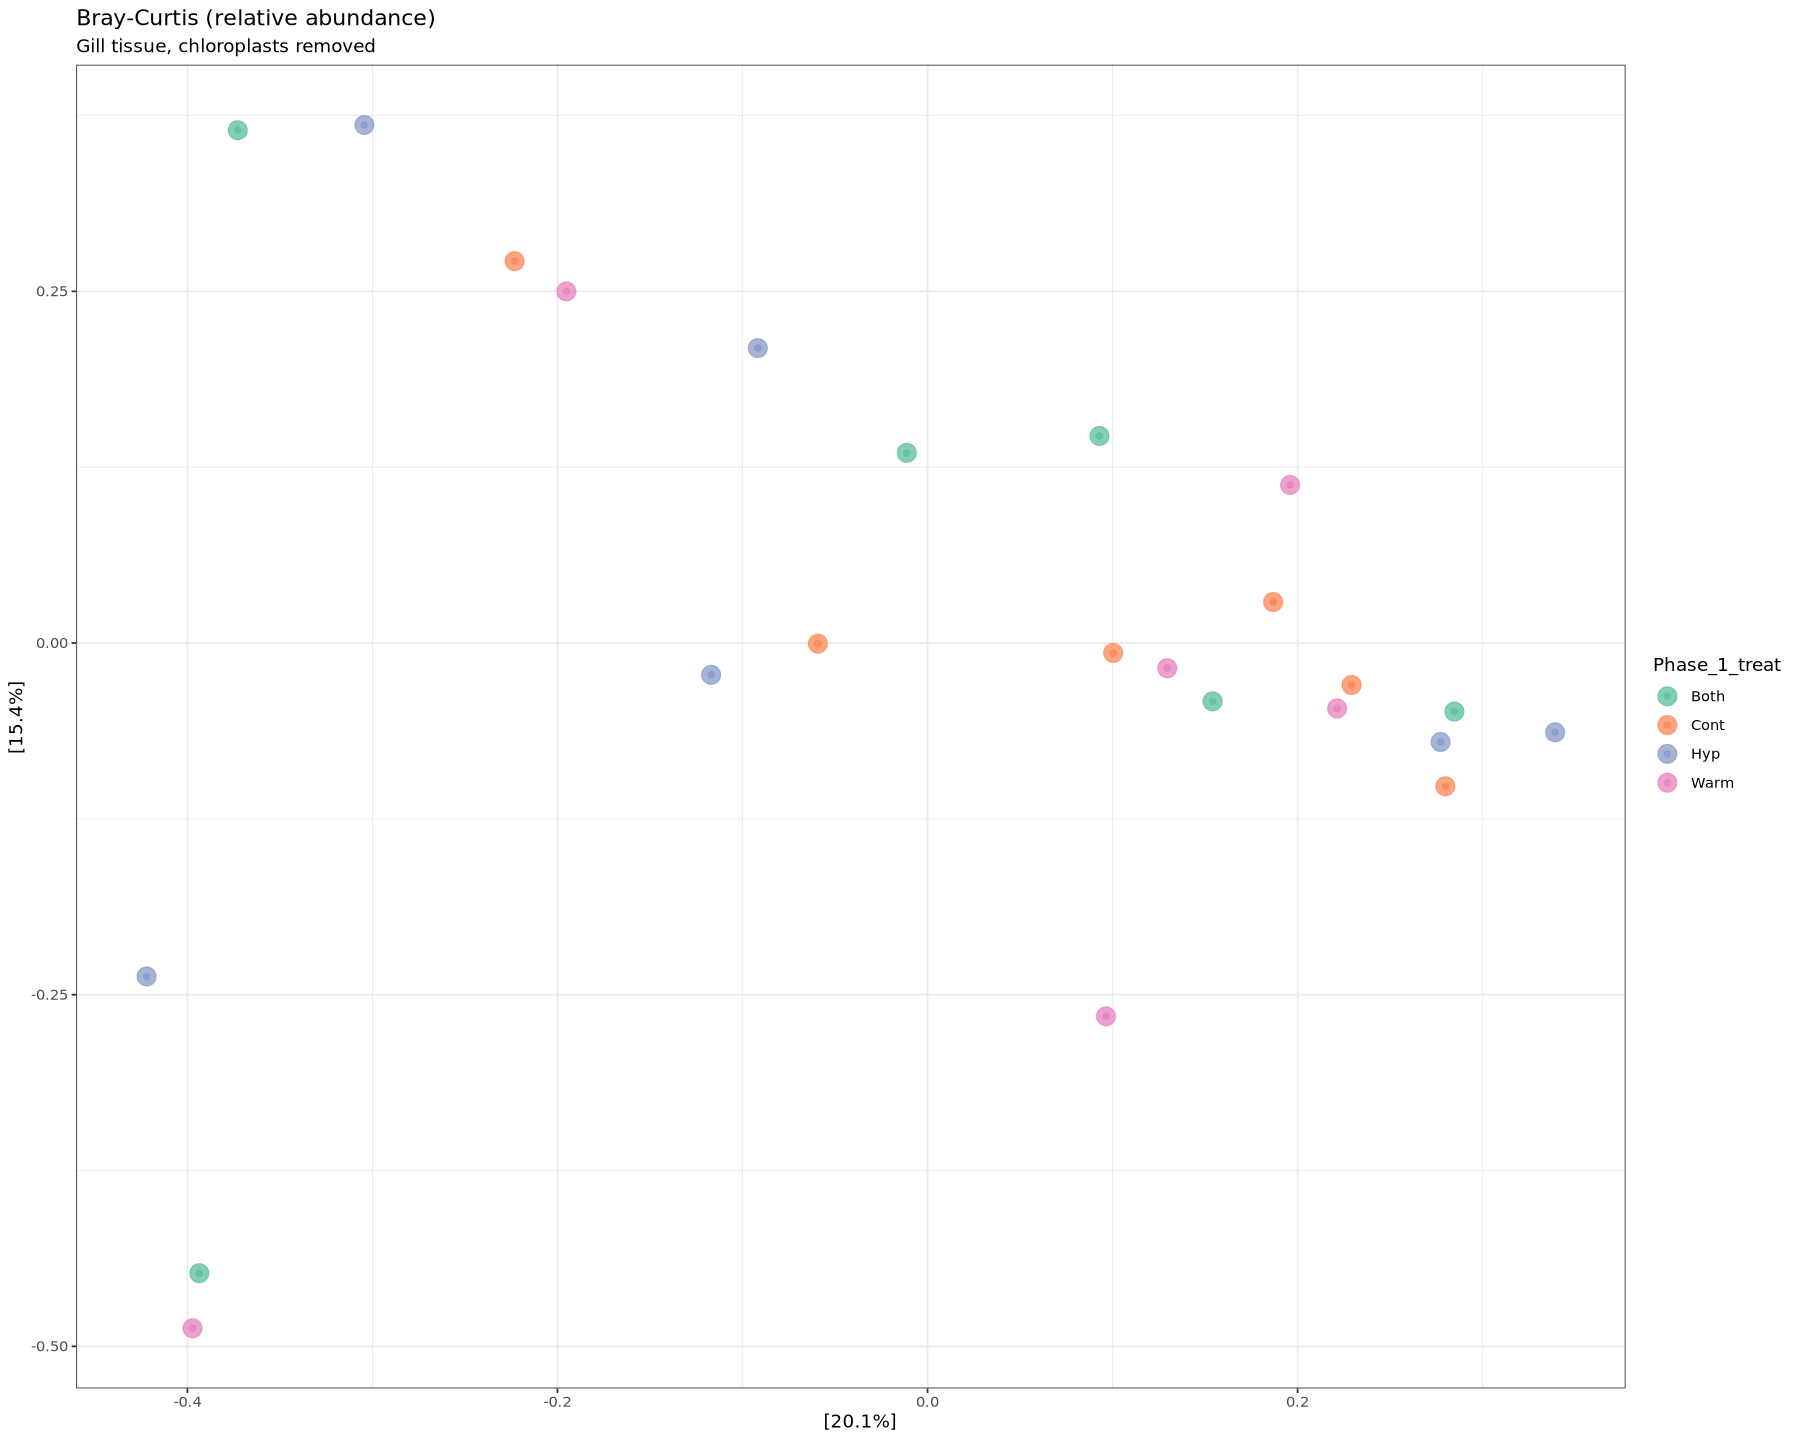

In [14]:
# Visualize PCoA
plot_ordination(ps_gill, pcoa_bray_gill, color = "Phase_1_treat") +
    geom_point(size = 5, alpha = 0.8) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "Bray-Curtis (relative abundance)", subtitle = "Gill tissue, chloroplasts removed") +
    theme_bw()

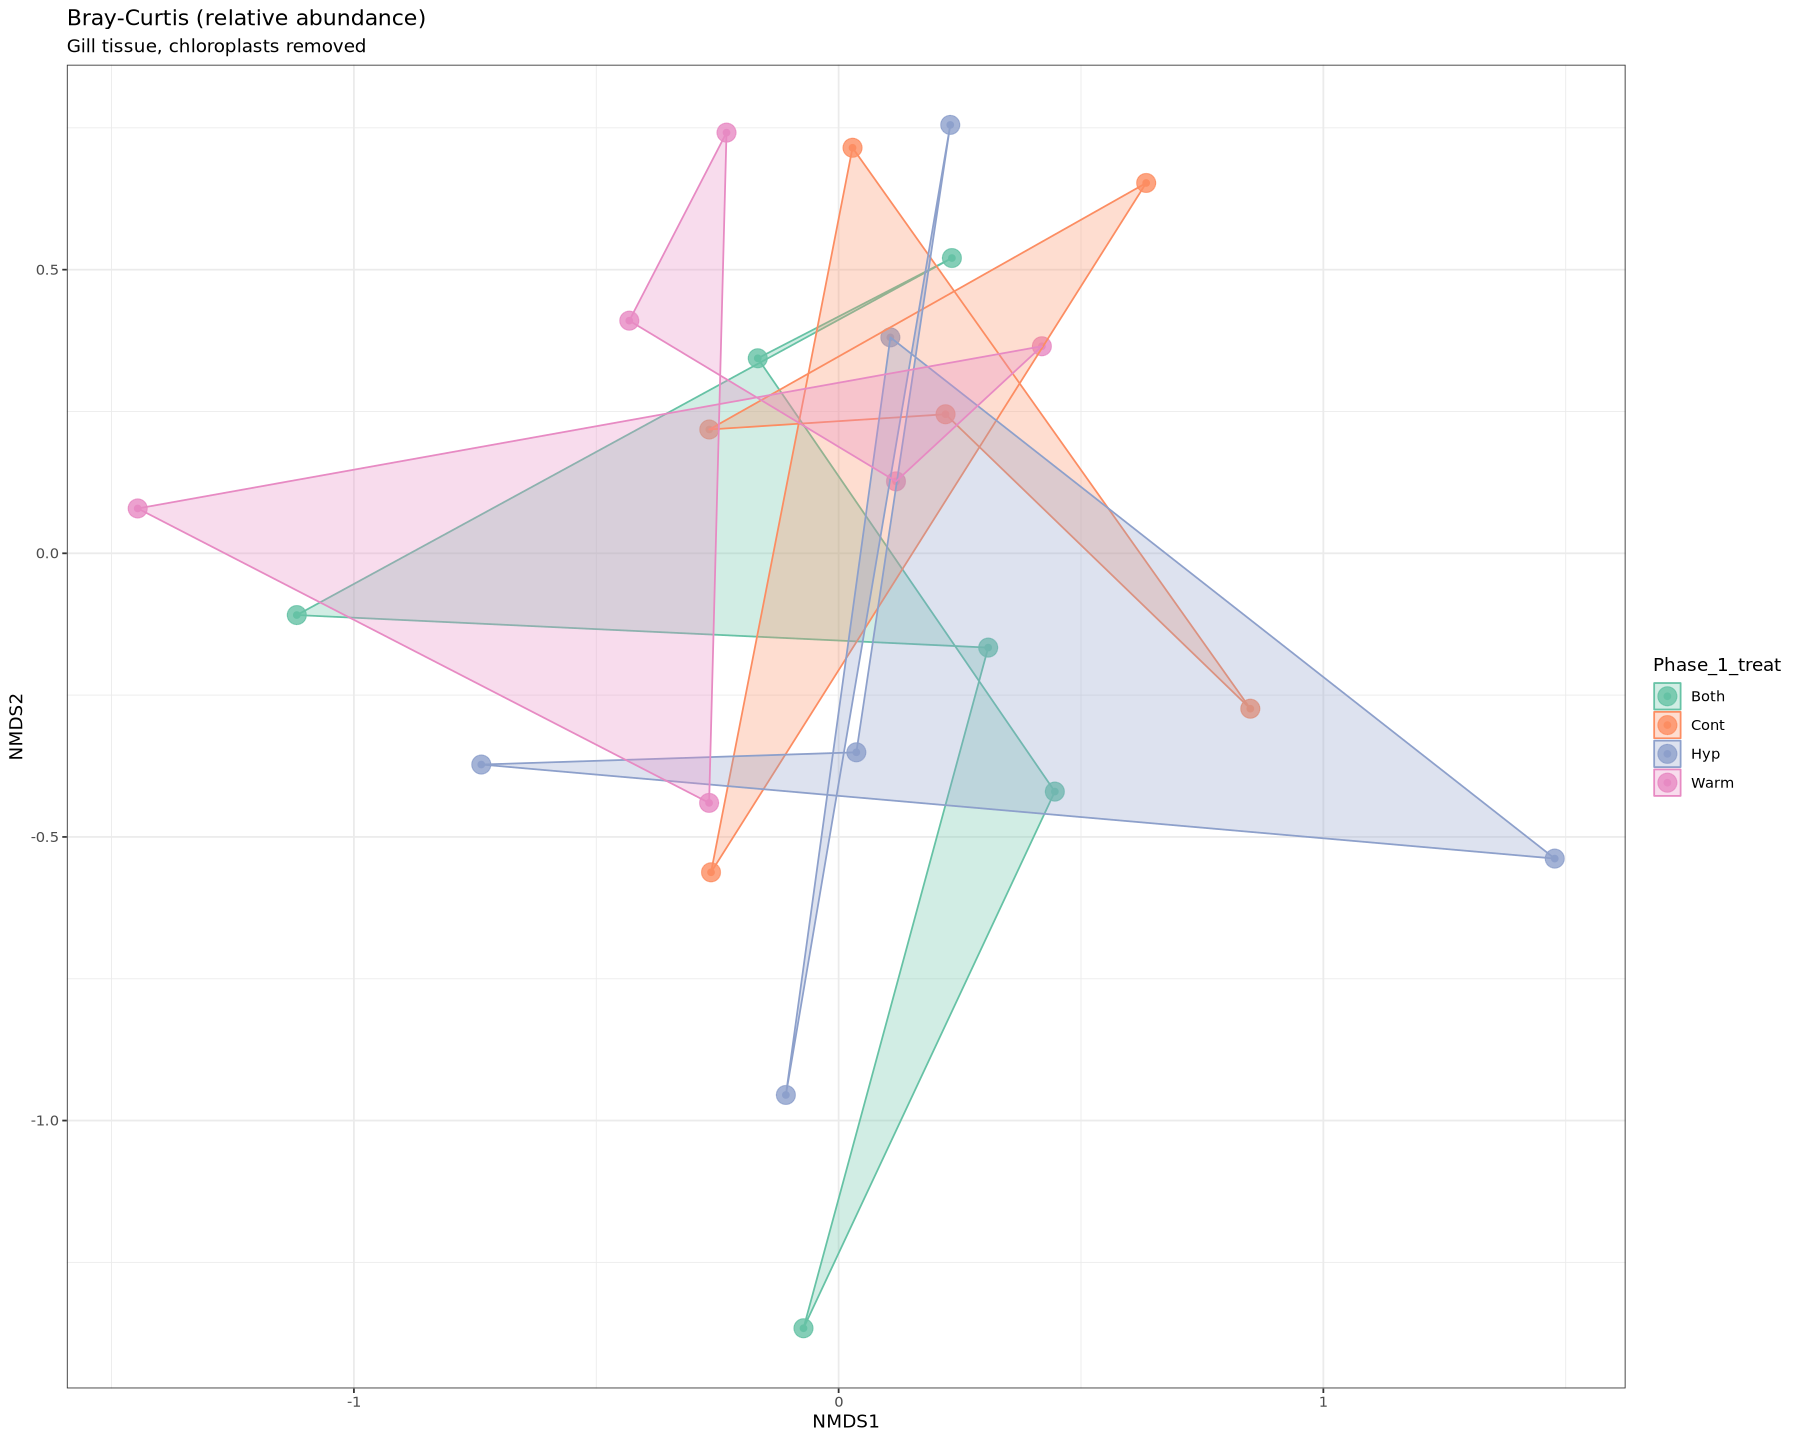

In [15]:
# Visualize nMDS
plot_ordination(ps_gill, nmds_bray_gill, type = "samples", color = "Phase_1_treat") +
    geom_point(size = 5, alpha = 0.8) +
    geom_polygon(aes(fill = Phase_1_treat), alpha=0.3) +
    scale_color_brewer(palette = "Set2") +
    scale_fill_brewer(palette = "Set2") +
    labs(title = "Bray-Curtis (relative abundance)", subtitle = "Gill tissue, chloroplasts removed") +
    theme_bw() 

### Gut only

Proceeding with chloroplasts removed, keeping with other published literature. 

In [8]:
# Subset gut samples in new phyloseq object
ps_gut <- subset_samples(ps_nc, Tissue == "gut")
ps_gut <- prune_taxa(taxa_sums(ps_gut) > 0, ps_gut)
ps_gut

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 6608 taxa and 24 samples ]
sample_data() Sample Data:       [ 24 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 6608 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 6608 reference sequences ]

In [9]:
# Compute bray-curtis distance matrix
dist_bray_gut <- phyloseq::distance(ps_gut, method = "bray")

# Ordinate using PCoA
pcoa_bray_gut <- ordinate(ps_gut, method = "PCoA", distance = dist_bray_gut)
pcoa_bray_gut$values$Relative_eig[1:5] %>% round(3)

# Ordinate using nMDS
nmds_bray_gut <- ordinate(ps_gut, method = "NMDS", distance = dist_bray_gut)
nmds_bray_gut$stress

[1] 0.181 0.145 0.095 0.083 0.076

Run 0 stress 0.09010494 
Run 1 stress 0.103877 
Run 2 stress 0.09029576 
... Procrustes: rmse 0.00858094  max resid 0.02066837 
Run 3 stress 0.09746877 
Run 4 stress 0.09932109 
Run 5 stress 0.1176394 
Run 6 stress 0.1108127 
Run 7 stress 0.1136919 
Run 8 stress 0.1281036 
Run 9 stress 0.1272662 
Run 10 stress 0.09651263 
Run 11 stress 0.1281052 
Run 12 stress 0.1272303 
Run 13 stress 0.1038764 
Run 14 stress 0.1085497 
Run 15 stress 0.09825827 
Run 16 stress 0.1181036 
Run 17 stress 0.1108125 
Run 18 stress 0.09010389 
... New best solution
... Procrustes: rmse 0.0007649016  max resid 0.002603648 
... Similar to previous best
Run 19 stress 0.103877 
Run 20 stress 0.110812 
*** Best solution repeated 1 times


[1] 0.09010389

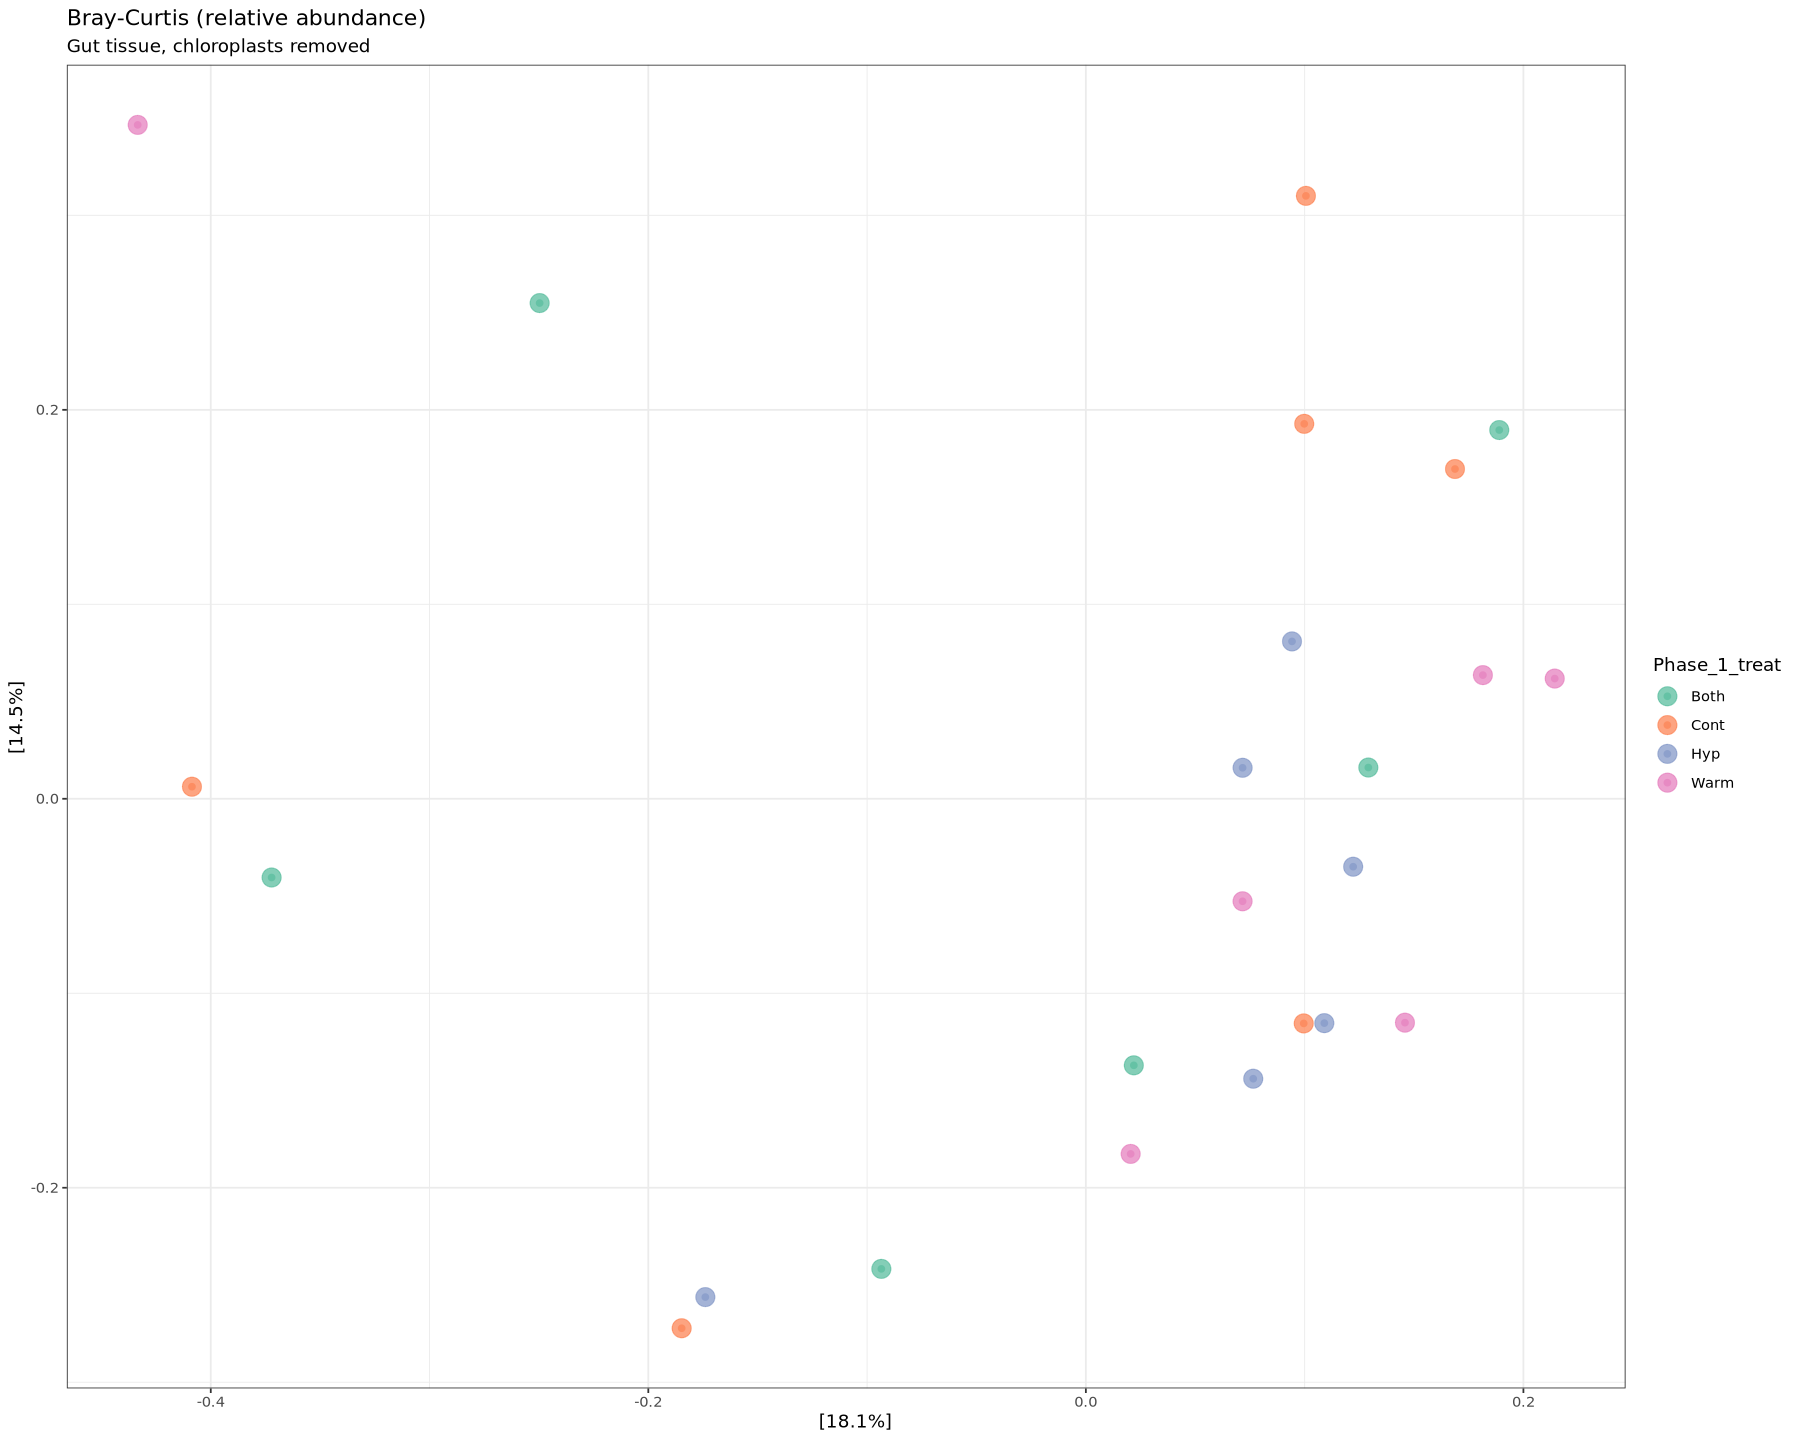

In [18]:
# Visualize PCoA
plot_ordination(ps_gut, pcoa_bray_gut, color = "Phase_1_treat") +
    geom_point(size = 5, alpha = 0.8) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "Bray-Curtis (relative abundance)", subtitle = "Gut tissue, chloroplasts removed") +
    theme_bw()

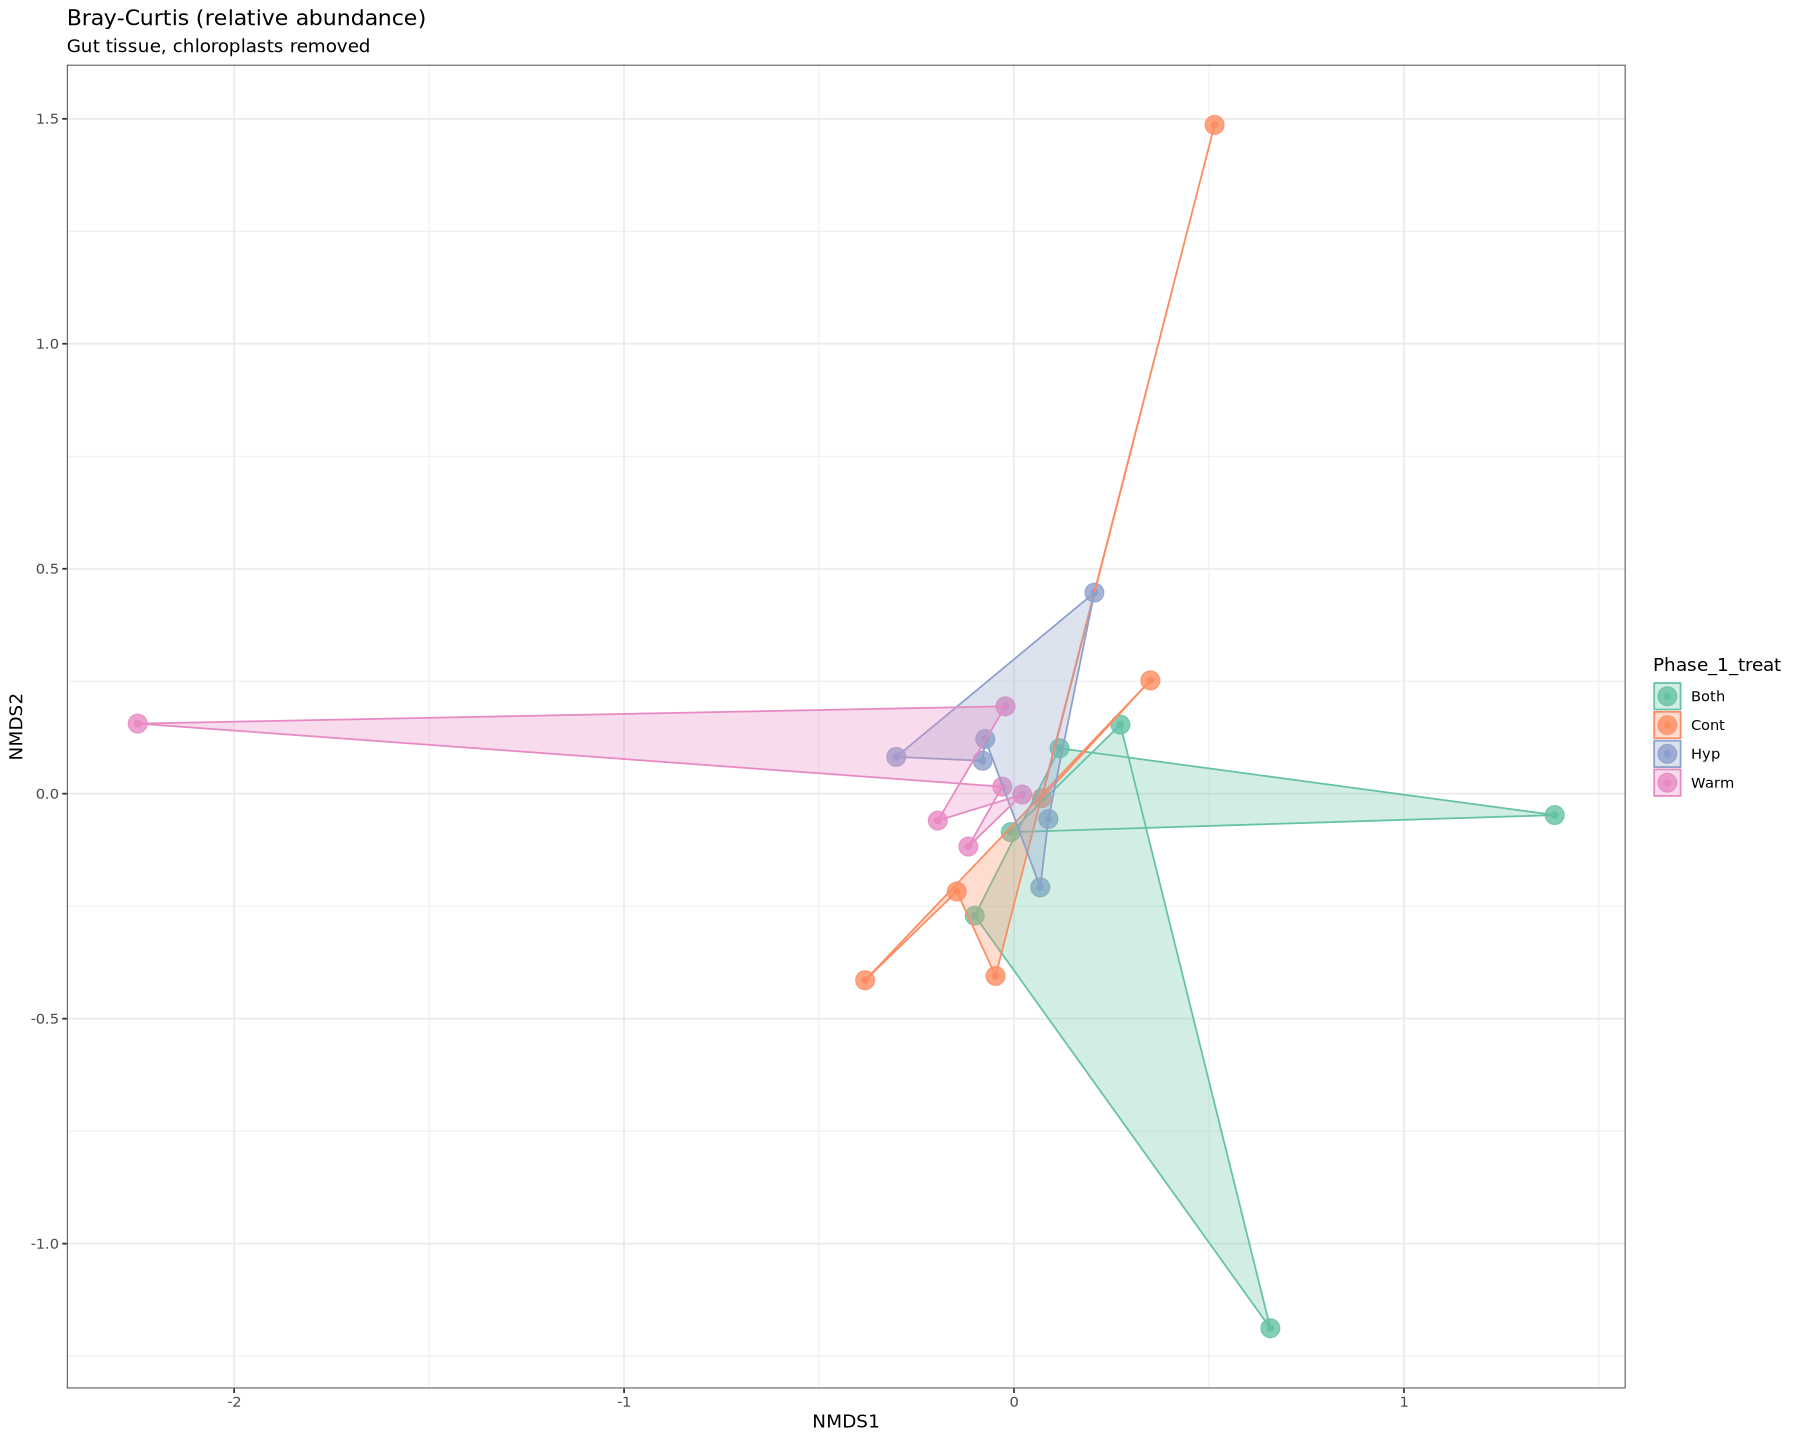

In [19]:
# Visualize nMDS
plot_ordination(ps_gut, nmds_bray_gut, type = "samples", color = "Phase_1_treat") +
    geom_point(size = 5, alpha = 0.8) +
    geom_polygon(aes(fill = Phase_1_treat), alpha=0.3) +
    scale_color_brewer(palette = "Set2") +
    scale_fill_brewer(palette = "Set2") +
    labs(title = "Bray-Curtis (relative abundance)", subtitle = "Gut tissue, chloroplasts removed") +
    theme_bw() 

In [17]:
# Convert phyloseq object sample data into metadata df
metadata_gut <- data.frame(sample_data(ps_gut))

# Align metadata with distance matrix
metadata_gut <- metadata[labels(dist_bray_gut), , drop = FALSE]

In [14]:
# PERMANOVA
permanova_gut <- adonis2(dist_bray_gut ~ Phase_1_treat, data = metadata, permutations = 999)
permanova_gut

,Df,SumOfSqs,R2,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Model,3,0.6546702,0.1325915,1.019062,0.4
Residual,20,4.2828267,0.8674085,NA,NA
Total,23,4.9374969,1.0000000,NA,NA


Phase 1 treatment explains 13% of the variation in beta diversity across all gut samples. There is no significant evidence that  microbiome composition differs based on Phase 1 treatment (p = 0.4).

In [15]:
# Check beta dispersion (variability within each treatment group)
disp_gut <- betadisper(dist_bray_gut, metadata$Phase_1_treat)
permutest(disp_gut, permutations = 999)


Permutation test for homogeneity of multivariate dispersions
Permutation: free
Number of permutations: 999

Response: Distances
          Df  Sum Sq  Mean Sq      F N.Perm Pr(>F)
Groups     3 0.03230 0.010767 0.5355    999  0.698
Residuals 20 0.40212 0.020106                     

No evidence that a Phase 1 treatment group has more microbiome variation than the others.

## 11.20.26 | alpha diversity exploration

Need to use data that retains singletons and is still raw counts as opposed to relative abundances in order to calculate alpha diversity.

In [73]:
# Load packages
suppressPackageStartupMessages({
    library(phyloseq)
    library(tidyverse)
    library(ggpubr)
})
    
options(repr.plot.width=15, repr.plot.height=8)

In [28]:
# Read in cleaned phyloseq object, singletons are preserved
ps_clean <- readRDS("/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ps-objects/ps-dada2-clean.rds")

In [29]:
# Subset phase 1 samples
ps_alpha <- subset_samples(ps_clean, Phase == 1 & Tissue != "filter")
ps_alpha <- prune_taxa(taxa_sums(ps_alpha) > 0, ps_alpha)
ps_alpha

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 10243 taxa and 48 samples ]
sample_data() Sample Data:       [ 48 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 10243 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 10243 reference sequences ]

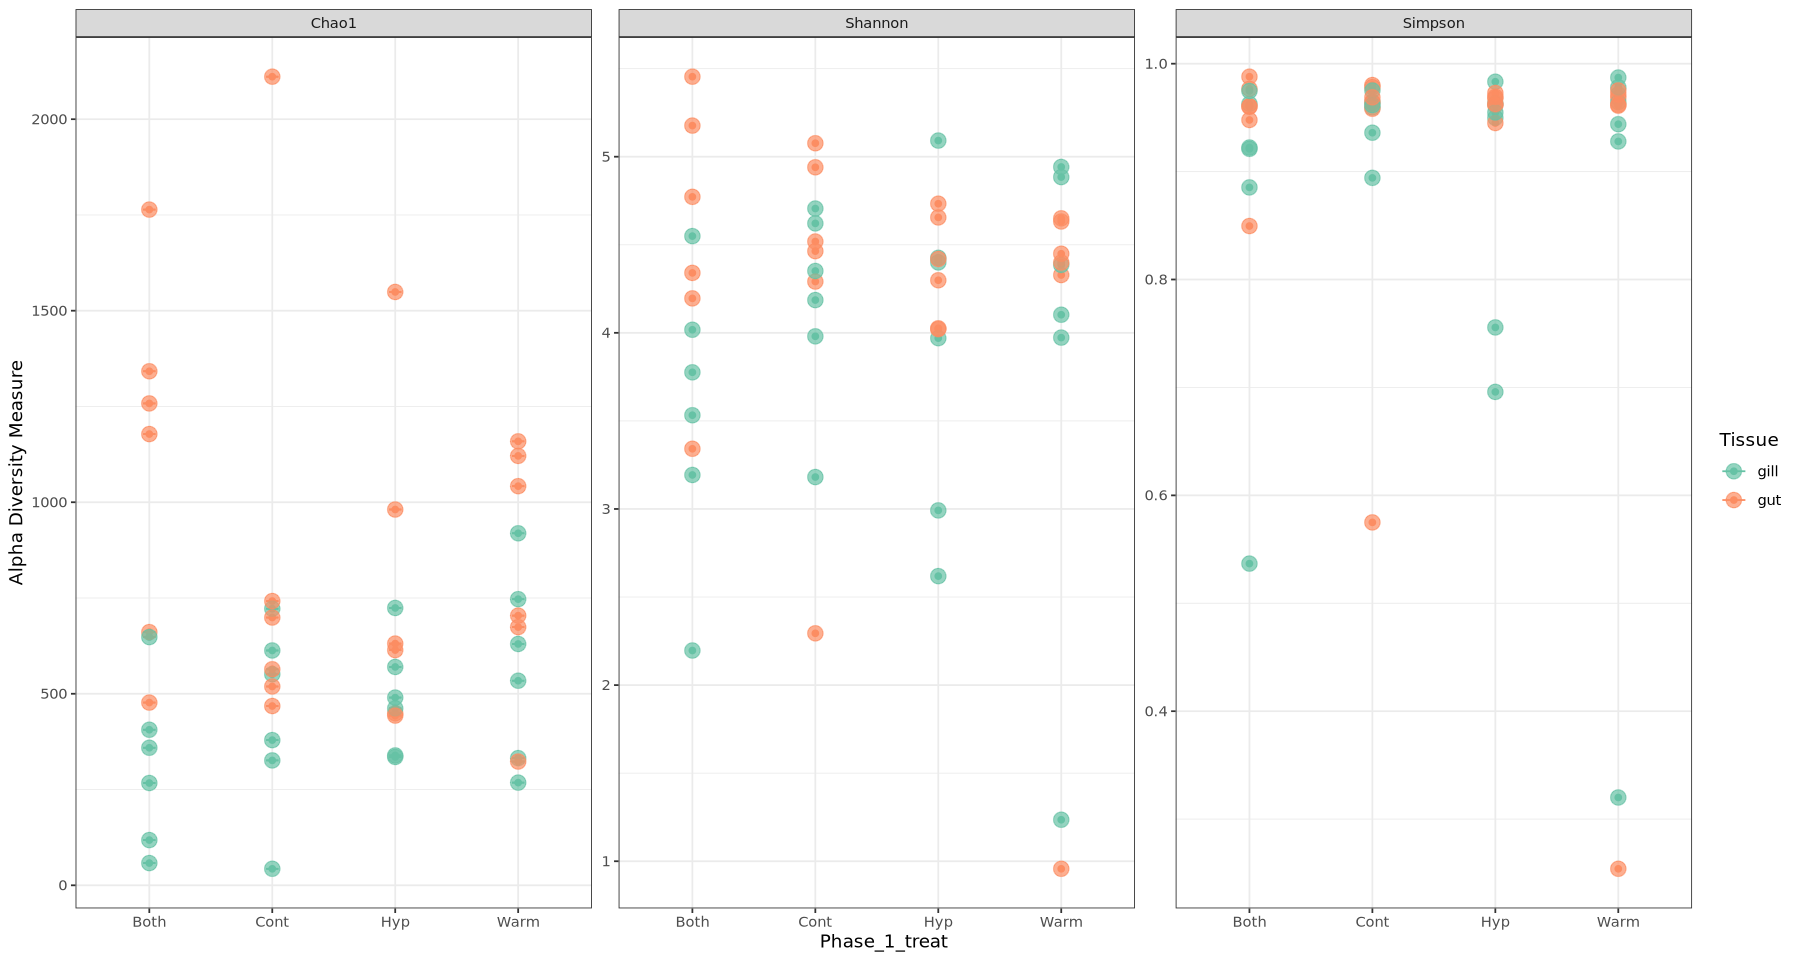

In [51]:
# Plot alpha diversity
plot_richness(ps_alpha, x = "Phase_1_treat", color = "Tissue", measures = c("Shannon", "Simpson", "Chao1")) +
    geom_point(alpha = 0.7, size = 4) +
    scale_color_brewer(palette = "Set2") +
    theme_bw()

### Gill only

In [52]:
# Only gill
ps_alpha_gill <- subset_samples(ps_alpha, Tissue == "gill")
ps_alpha_gill <- prune_taxa(taxa_sums(ps_alpha_gill) > 0, ps_alpha_gill)
ps_alpha_gill

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 4667 taxa and 24 samples ]
sample_data() Sample Data:       [ 24 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 4667 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 4667 reference sequences ]

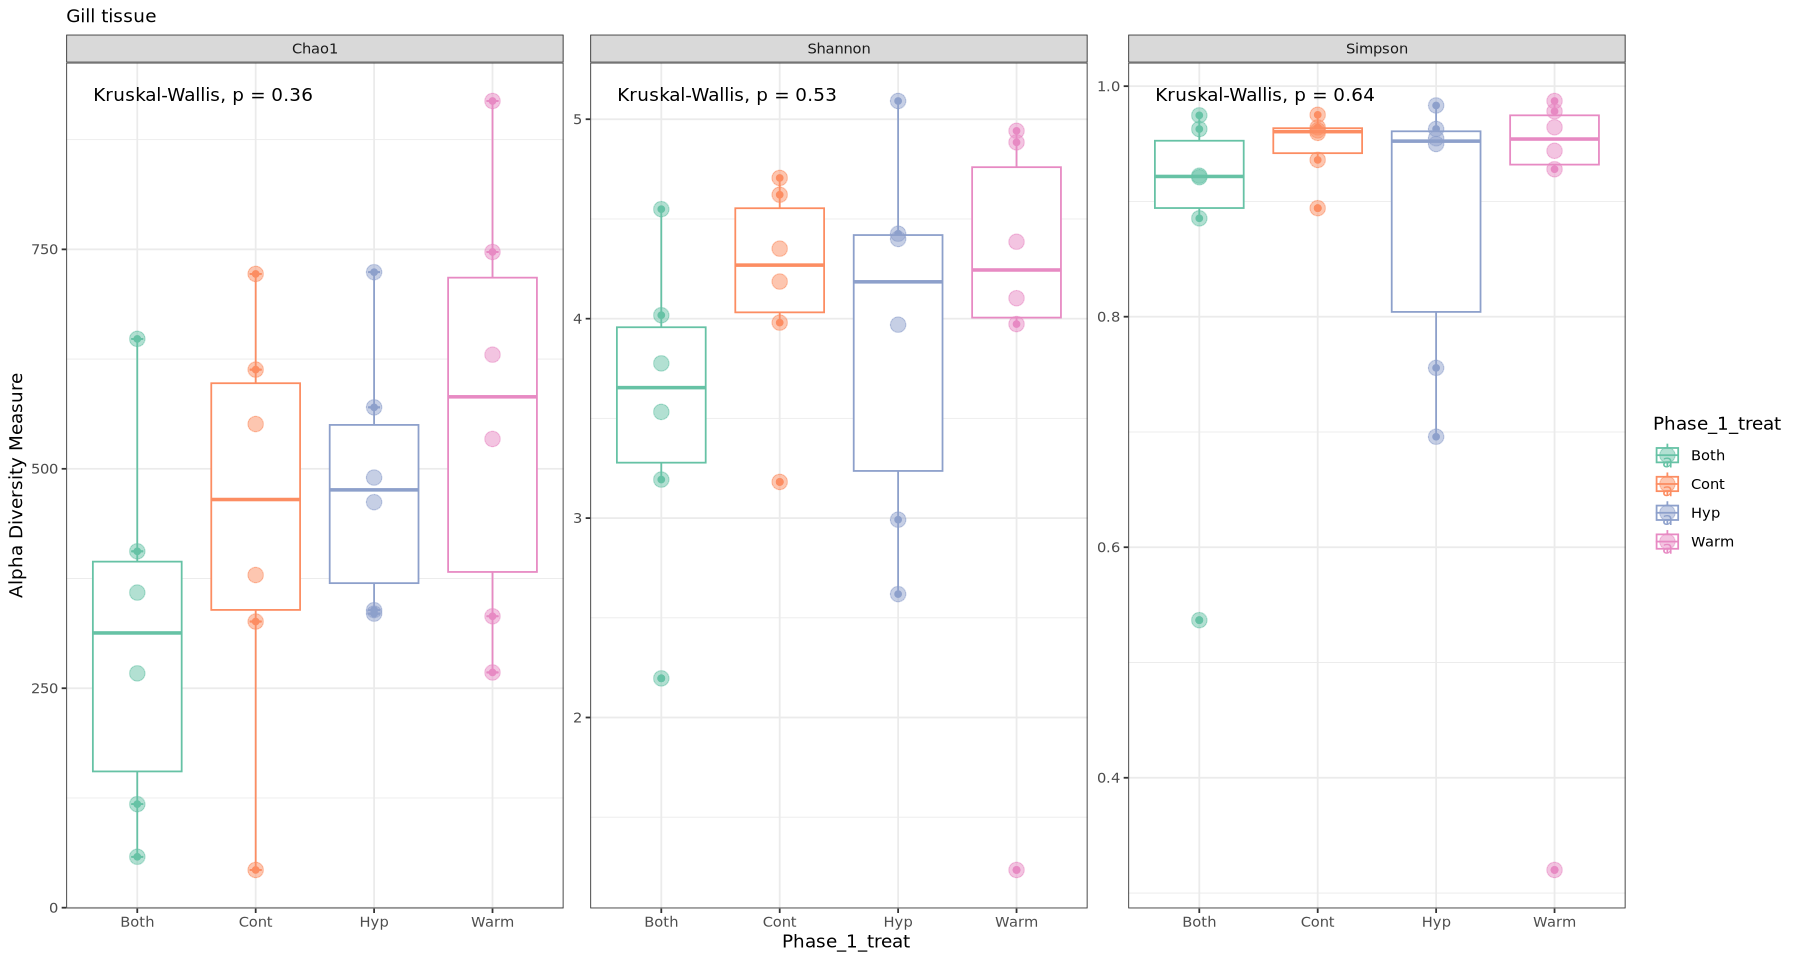

In [82]:
# Plot alpha diversity
plot_richness(ps_alpha_gill, x = "Phase_1_treat", color = "Phase_1_treat", measures = c("Shannon", "Simpson", "Chao1")) +
    geom_boxplot() +
    geom_point(alpha = 0.5, size = 4) +
    scale_color_brewer(palette = "Set2") +
    labs(subtitle = "Gill tissue") +
    stat_compare_means(method = "kruskal.test") +
    theme_bw()

In [63]:
# Only gill, remove chloroplasts
ps_alpha_gill_nc <- subset_taxa(ps_alpha_gill, Order != "Chloroplast")
ps_alpha_gill_nc <- prune_taxa(taxa_sums(ps_alpha_gill_nc) > 0, ps_alpha_gill_nc)
ps_alpha_gill_nc

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 4204 taxa and 24 samples ]
sample_data() Sample Data:       [ 24 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 4204 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 4204 reference sequences ]

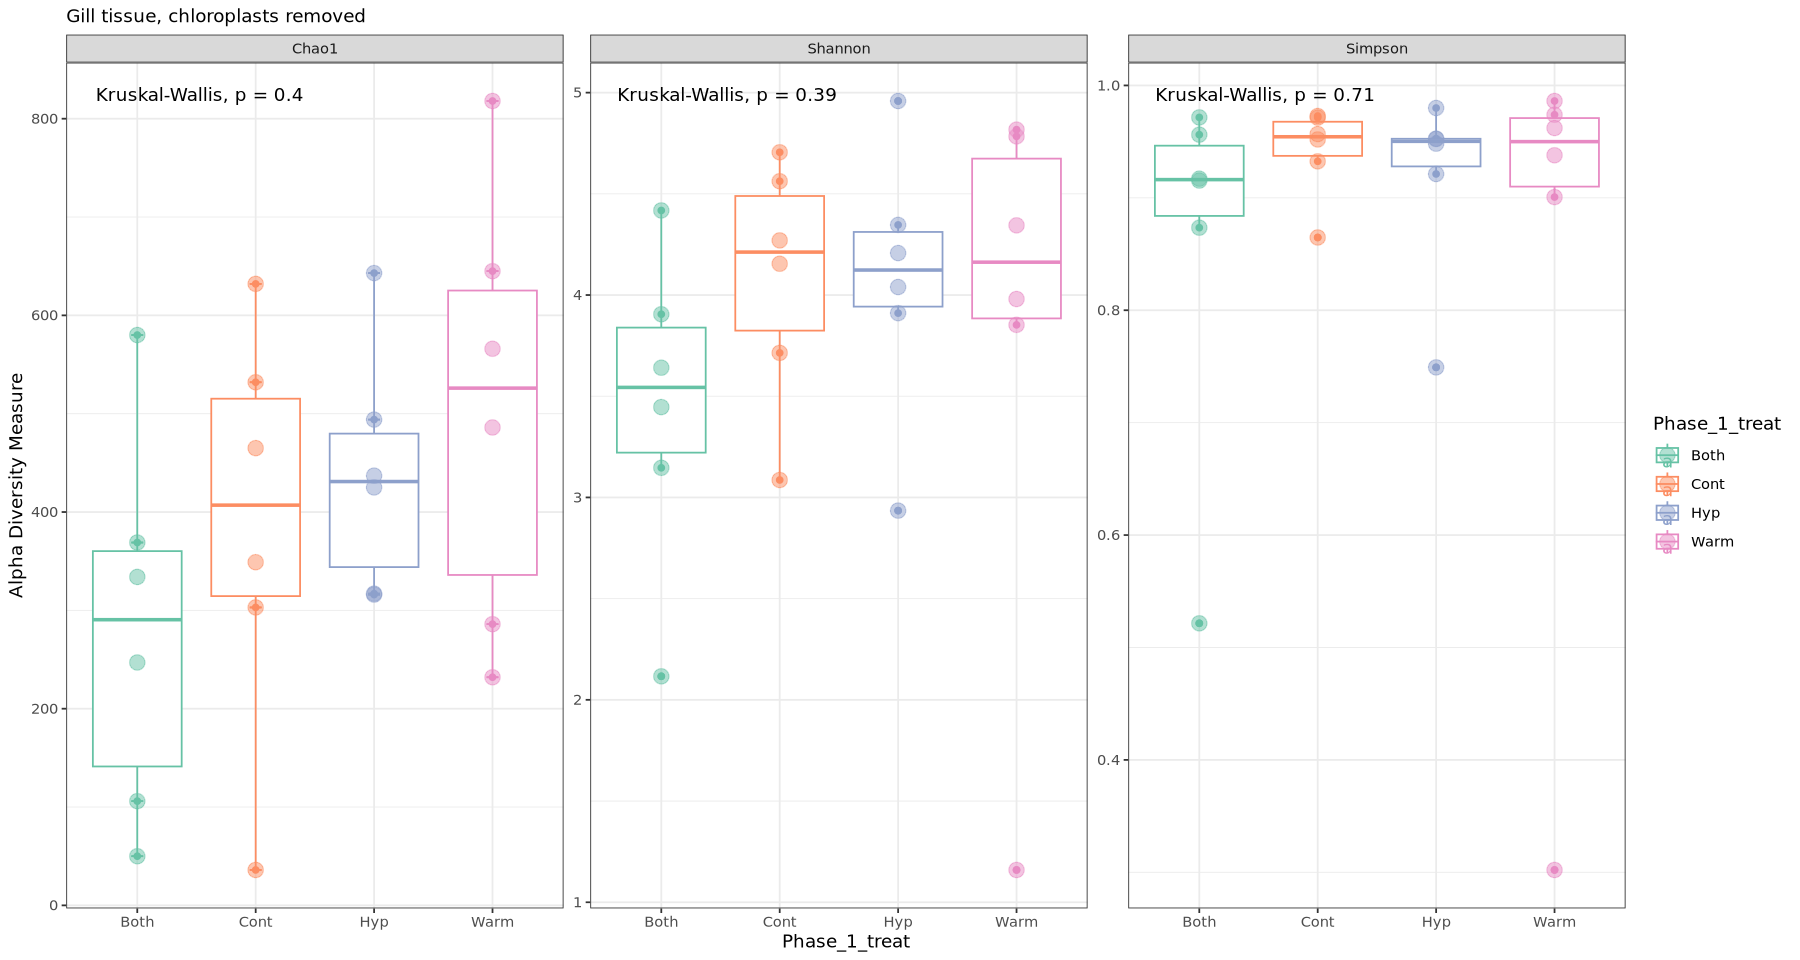

In [83]:
# Plot alpha diversity
plot_richness(ps_alpha_gill_nc, x = "Phase_1_treat", color = "Phase_1_treat", measures = c("Shannon", "Simpson", "Chao1")) +
    geom_boxplot() +
    geom_point(alpha = 0.5, size = 4) +
    scale_color_brewer(palette = "Set2") +
    labs(subtitle = "Gill tissue, chloroplasts removed") +
    stat_compare_means(method = "kruskal.test") +
    theme_bw()

### Gut only

In [69]:
# Only gut
ps_alpha_gut <- subset_samples(ps_alpha, Tissue == "gut")
ps_alpha_gut <- prune_taxa(taxa_sums(ps_alpha_gut) > 0, ps_alpha_gut)
ps_alpha_gut

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 7823 taxa and 24 samples ]
sample_data() Sample Data:       [ 24 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 7823 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 7823 reference sequences ]

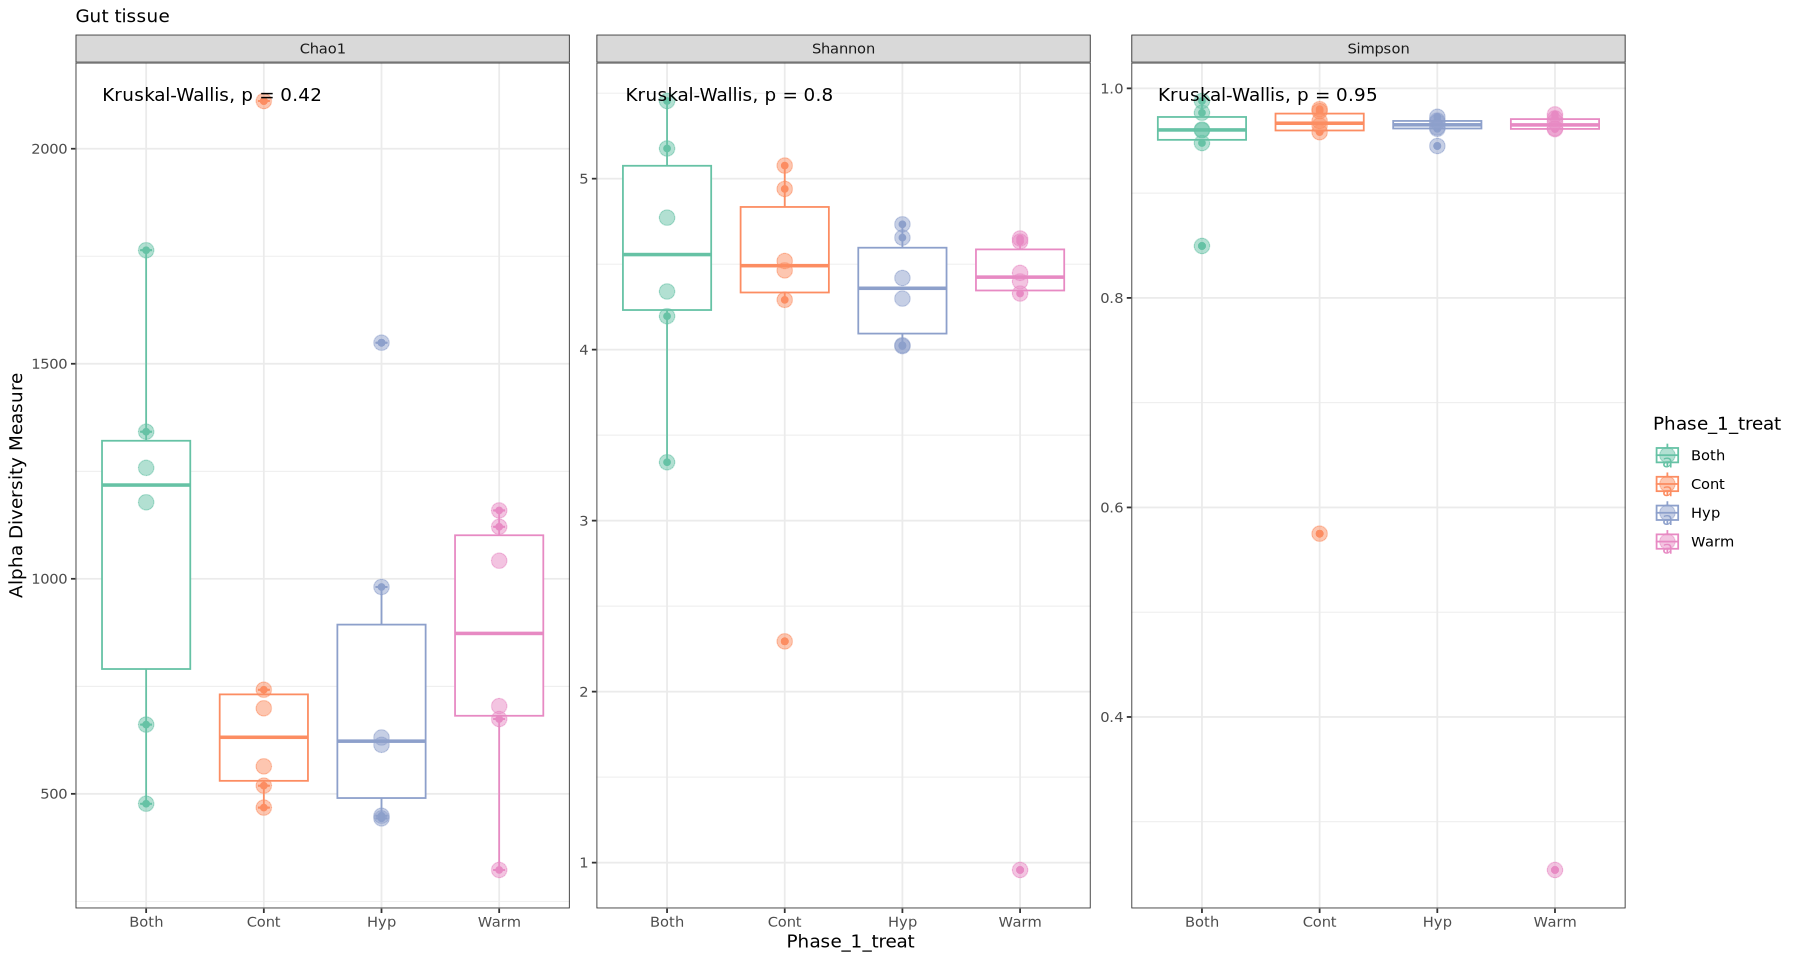

In [84]:
# Plot alpha diversity
plot_richness(ps_alpha_gut, x = "Phase_1_treat", color = "Phase_1_treat", measures = c("Shannon", "Simpson", "Chao1")) +
    geom_boxplot() +
    geom_point(alpha = 0.5, size = 4) +
    scale_color_brewer(palette = "Set2") +
    labs(subtitle = "Gut tissue") +
    stat_compare_means(method = "kruskal.test") +
    theme_bw()

In [65]:
# Only gut
ps_alpha_gut_nc <- subset_taxa(ps_alpha_gut, Order != "Chloroplast")
ps_alpha_gut_nc <- prune_taxa(taxa_sums(ps_alpha_gut_nc) > 0, ps_alpha_gut_nc)
ps_alpha_gut_nc

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 6700 taxa and 24 samples ]
sample_data() Sample Data:       [ 24 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 6700 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 6700 reference sequences ]

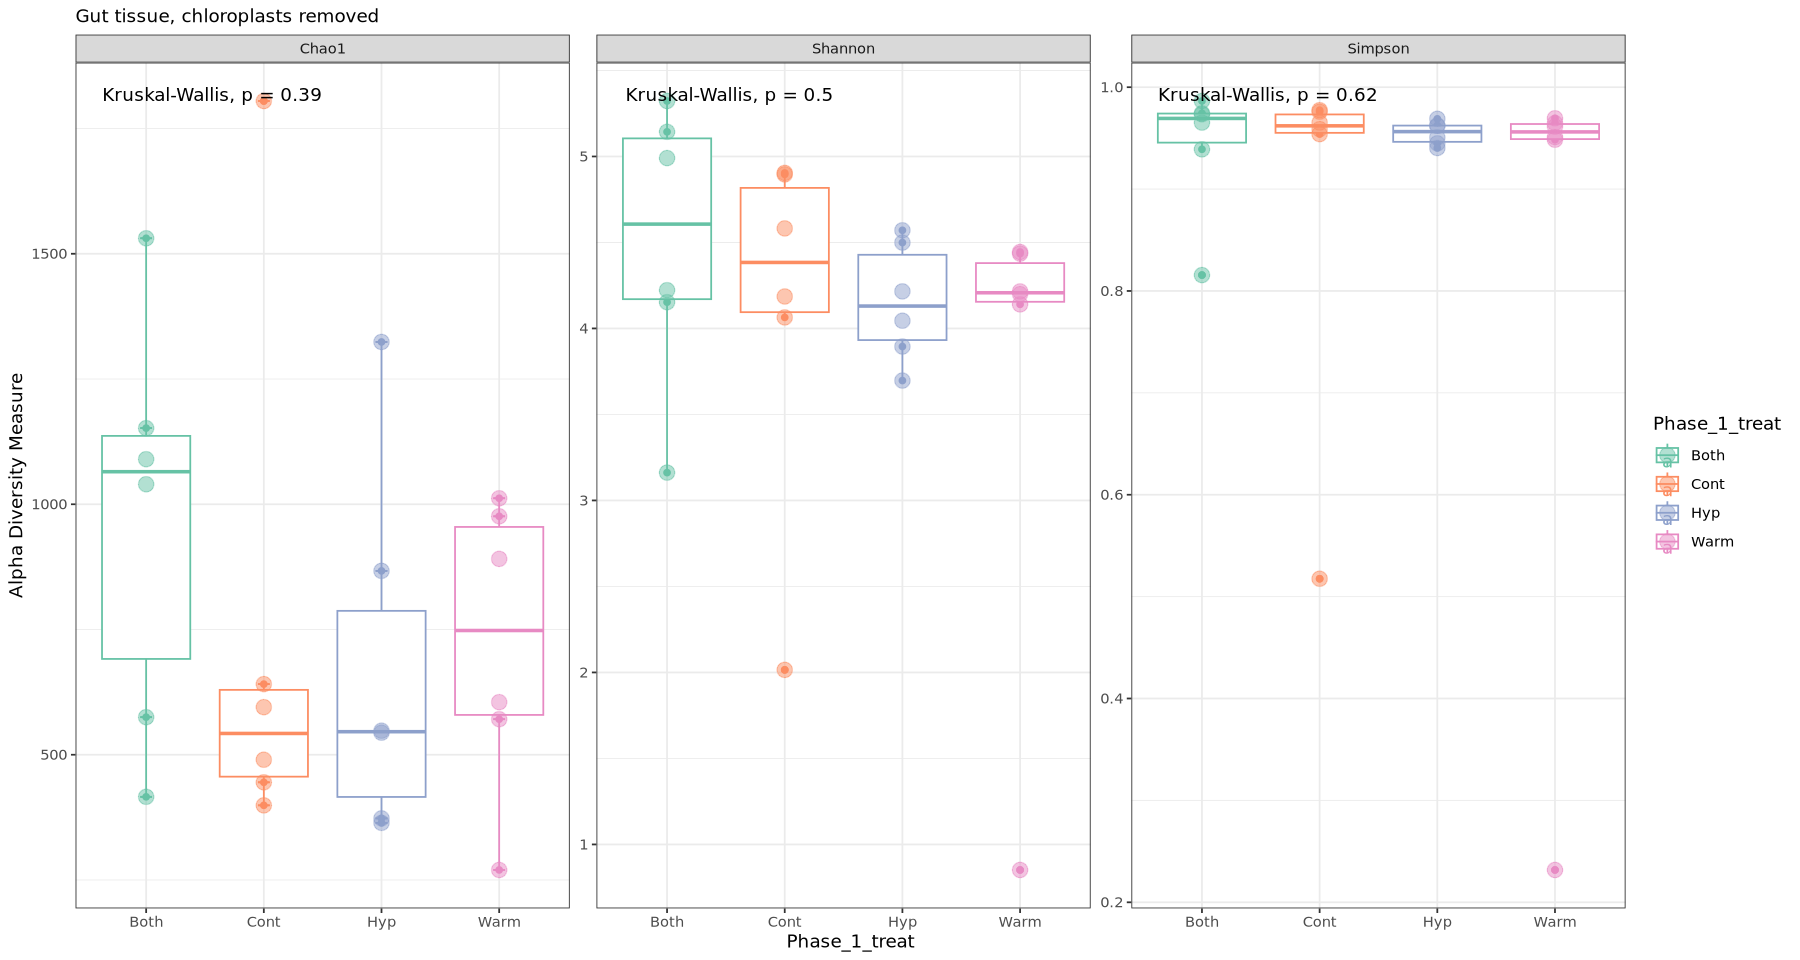

In [85]:
# Plot alpha diversity
plot_richness(ps_alpha_gut_nc, x = "Phase_1_treat", color = "Phase_1_treat", measures = c("Shannon", "Simpson", "Chao1")) +
    geom_boxplot() +
    geom_point(alpha = 0.5, size = 4) +
    scale_color_brewer(palette = "Set2") +
    labs(subtitle = "Gut tissue, chloroplasts removed") +
    stat_compare_means(method = "kruskal.test") +
    theme_bw()